# Training loss, no-signal cells and edges: a study of RMTransformer radio map prediction

**Project:** Neural Prediction of RF Coverage Maps for Drone Missions (AIRWISE, Politecnico di Milano)<br>
**Data:** [AIRWISE synthetic urban RF coverage maps](https://huggingface.co/datasets/TYessine/airwise-rf-coverage-maps):
path gain maps at 2.4 GHz from a ground station to a drone flying at 15, 30, 45 or 60 m above 128 m × 128 m
synthetic city blocks, ray traced with Sionna RT<br>
**Model:** RMTransformer ([Li et al., 2025](https://arxiv.org/abs/2501.05190)), a hybrid transformer / CNN
encoder-decoder, adapted to drone altitudes

### Objective
This notebook answers three questions, each building on the previous one:
1. **Training loss.** Which loss function gives the most accurate coverage maps? Four losses are compared on the
   smallest model configuration: MSE, L1, Huber and a combined loss (L1 + MSE + SSIM + gradient) taken from recent
   radio map literature.
2. **No-signal cells.** Cells that no ray reaches are stored at −150 dB and dominate the remaining error. Five ways
   of treating them and the other weak-signal cells during training are compared with the retained loss:
   truncation, censored target, separate signal / no-signal output, asymmetric penalty on overestimation and
   re-weighting of rare path gain values.
3. **Edges of the coverage map.** Most of the remaining error lies near sharp transitions of the map (shadow
   borders). Ways of improving the edges are compared: a line-of-sight input channel computed from the
   geometry, an edge-weighted loss, edge-detection input channels added on top of the line-of-sight input, and a continuous
   line-of-sight input (clearance) added to the best of them.

Finally, the best configuration found (combined loss; line-of-sight, building-edge and clearance inputs) is trained for
60 epochs instead of
20, to measure how much longer training improves it.

### Experimental protocol
All experiments share the same data, inputs, training schedule and metrics. Only the loss (study 1), the treatment
of no-signal cells (study 2) or the edge method (study 3) changes.

| setting | value |
|---|---|
| training data | `train` split: 1,080 scenes, 12,960 maps (families blocks, grid, downtown) |
| model selection | `val` split (135 scenes, 1,620 maps): every choice (checkpoint, loss, treatment of no-signal cells) is made on validation results only |
| reported on | `test` (135 scenes of the training families, never seen) and `ood` (270 scenes of the unseen families canyon, courtyard, hilly) |
| batch size, epochs | 16, 20 (810 steps per epoch, 16,200 steps in total) |
| optimiser | Adam, learning rate 1e-4 with 500 warm-up steps and cosine decay to 1e-5, gradient clipping at 1 |
| other | bf16 mixed precision, random rotations and mirrors (8 symmetries of the square), stochastic depth 0.1 |
| reproducibility | fixed seed: every run of a given model size starts from the same initial weights and sees the batches in the same order |

| study | experiments |
|---|---|
| 1. loss (model `tiny`) | `tiny_mse`, `tiny_l1`, `tiny_huber`, then `tiny_combo` |
| 2. no-signal cells (model `tiny`, retained loss) | baseline, `truncate`, `censor`, `two_output`, `asymmetric`, `reweight` |
| 3. edges (model `tiny`, retained loss) | baseline, `los` (line-of-sight input), `edgeweight` (edge-weighted loss), `los_losedge` and `los_heightedge` (edge-detection inputs on top of `los`), `los_heightedge_clearance` (+ clearance) |
| seed check | the last 3 configurations of study 3 (edge-detection and clearance inputs), retrained with seeds 1 and 2 |
| final model | `los_heightedge_clearance` trained for 60 epochs (`los` trained for 60 epochs as reference) |

### Contents
1. Setup
2. Data
3. Model inputs and target
4. Model: RMTransformer
5. Loss functions and treatment of no-signal cells
6. Evaluation metrics
7. Training procedure and experiment runner
8. Study 1: training loss
9. Why the error remains high: the no-signal cells
10. Study 2: treatment of the no-signal cells
11. Where the error lies: the edges of the coverage map
12. Study 3: edges of the coverage map
13. Final model: longer training

## 1. Setup

In [1]:
import json
import math
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

try:
    from tqdm.auto import tqdm
except ImportError:              # progress bars are optional
    tqdm = None

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
# bf16 needs no loss scaling. Older GPUs without bf16 fall back to fp16 with a GradScaler.
AMP_DTYPE = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16

print("torch", torch.__version__, "| device:", DEVICE,
      f"({torch.cuda.get_device_name(0)}, AMP {AMP_DTYPE})" if DEVICE.type == "cuda" else "(no GPU found)")


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

torch 2.15.0+cu132 | device: cuda (NVIDIA GeForce RTX 4070 Laptop GPU, AMP torch.bfloat16)


In [2]:
CFG = dict(
    # --- data
    repo_id="TYessine/airwise-rf-coverage-maps",
    revision=None,                # pin a commit hash or tag of the dataset repo for reproducibility
    data_dir=None,                # folder that already holds <split>.npz (None = download from the Hub)
    splits=("train", "val", "test", "ood"),
    study_dir="runs/loss_and_size_study",   # one sub-folder per experiment
    seed=0,
    # --- physics and normalisation
    freq_hz=2.4e9,
    floor_db=-150.0,              # dataset floor: -150 dB means no ray arrived
    max_db=-50.0,                 # top of the [0, 1] scale (highest gain in the data is about -54 dB)
    height_scale=60.0,            # m, heights, altitudes and station z are divided by this
    tx_sigma=1.0,                 # cells, width of the Gaussian station marker
    in_channels=("height", "rel_height", "valid", "tx", "fspl", "tx_z", "altitude"),
    # --- model
    model_size="tiny",            # "tiny": 32-256 channels, "small": 64-512, "paper": 128-1024 (as in the paper)
    window=8,                     # MaxViT block size P and grid size G
    head_dim=32,
    mbconv_expand=4,
    drop_path=0.1,
    # --- training (the RMTransformer paper uses 50 epochs and batch 8; all runs here use 20 and 16)
    epochs=20,
    batch_size=16,
    lr=1e-4,
    min_lr=1e-5,
    warmup_steps=500,
    weight_decay=0.0,             # 0 = plain Adam as in the paper
    grad_clip=1.0,
    augment=True,                 # random 90 degree rotations and mirroring (see the input section)
    amp=True,
    loss="mse",                   # "mse", "l1", "huber" or "combo" (set per experiment)
    huber_delta=0.05,             # Huber threshold in [0, 1] units: 0.05 = 5 dB
    loss_weights=dict(l1=0.4, mse=0.1, ssim=0.2, grad=0.3),   # combined loss (RadioMamba weights)
    floor_method="none",          # "none", "truncate", "censor", "two_output", "asymmetric" or "reweight" (section 10)
    floor_threshold_db=-130.0,    # path gain below which no drone link is possible (section 10)
    signal_loss_weight=0.1,       # weight of the signal / no-signal classification loss ("two_output")
    weak_db=-110.0,               # "asymmetric": cells weaker than this are weak-signal cells
    asym_factor=4.0,              # "asymmetric": an overestimation in a weak-signal cell counts this many times
    reweight_bin_db=5.0,          # "reweight": width of the path gain bins (dB)
    reweight_table=None,          # "reweight": weight of each bin, computed from the training data (section 10)
    select_metric="rmse_db",      # validation metric used to keep the best checkpoint of a run
    # --- edges of the coverage map (sections 11 and 12)
    edge_threshold_db=3.0,        # a cell is an edge where the ray traced map changes by >= this many dB per cell
    edge_width=2,                 # cells within this distance of an edge are "near an edge"
    edge_weight=1.0,              # weight of the cells near an edge in the loss (1 = no edge weighting)
    los_samples=96,               # points checked along each station-to-cell segment for the "los" channel
    eval_batch_size=32,
    max_val_maps=None,            # validate on an evenly spaced subset each epoch to save time (None = all)
    # --- evaluation
    coverage_thresholds_db=(-80.0, -100.0, -110.0),   # path gain needed for a link, e.g. -110 dB = 20 dBm Tx, -90 dBm Rx
    boundary_width=2,             # cells on each side of the coverage boundary counted as "boundary"
)

MODEL_PRESETS = dict(
    tiny=dict(stem_dim=32, dims=(32, 64, 128, 256), depths=(1, 1, 1, 1)),
    small=dict(stem_dim=64, dims=(64, 128, 256, 512), depths=(1, 1, 1, 1)),
    paper=dict(stem_dim=128, dims=(128, 256, 512, 1024), depths=(1, 1, 1, 1)),
)

STUDY_DIR = Path(CFG["study_dir"])
STUDY_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(CFG["seed"])

## 2. Data
Each split is a NumPy file with the height map of every scene and, for every map, the station position, the drone
altitude and the ray traced path gain (dB). A cell is **valid** where a drone can be, i.e. where the drone plane is
above the surface: `height < altitude − 0.5 m`. Cells inside buildings taller than the drone are excluded from the
loss and from every metric.

| split | families | scenes | maps |
|---|---|---|---|
| train | blocks, grid, downtown | 1,080 | 12,960 |
| val | blocks, grid, downtown | 135 | 1,620 |
| test | blocks, grid, downtown | 135 | 1,620 |
| ood | canyon, courtyard, hilly | 270 | 3,240 |

Path gain is stored in dB and floored at −150 dB, the value used where no ray reached the cell.

In [3]:
from huggingface_hub import hf_hub_download

# The dataset repository is private: a Hugging Face token with access is required (hf auth login).

paths = {}
for split in CFG["splits"]:
    if CFG["data_dir"] is not None:
        paths[split] = Path(CFG["data_dir"]) / f"{split}.npz"
    else:
        paths[split] = Path(hf_hub_download(CFG["repo_id"], f"{split}.npz", repo_type="dataset",
                                            revision=CFG["revision"]))
    print(f"{split:5s} {paths[split]}  ({paths[split].stat().st_size / 1e6:.0f} MB)")

try:   # the exact ray tracing settings, kept with the run for reference
    rt_settings = json.loads(Path(hf_hub_download(CFG["repo_id"], "settings.json", repo_type="dataset",
                                                  revision=CFG["revision"])).read_text())
    (STUDY_DIR / "rt_settings.json").write_text(json.dumps(rt_settings, indent=2))
    print("ray tracing settings:", {k: rt_settings[k] for k in ("frequency", "samples", "max_depth") if k in rt_settings})
except Exception as e:
    print("settings.json not read:", e)

train C:\Users\ASUS\.cache\huggingface\hub\datasets--TYessine--airwise-rf-coverage-maps\snapshots\c00b7ff8873213ed9e083125b2c101de5a6f4808\train.npz  (660 MB)
val   C:\Users\ASUS\.cache\huggingface\hub\datasets--TYessine--airwise-rf-coverage-maps\snapshots\c00b7ff8873213ed9e083125b2c101de5a6f4808\val.npz  (83 MB)
test  C:\Users\ASUS\.cache\huggingface\hub\datasets--TYessine--airwise-rf-coverage-maps\snapshots\c00b7ff8873213ed9e083125b2c101de5a6f4808\test.npz  (82 MB)
ood   C:\Users\ASUS\.cache\huggingface\hub\datasets--TYessine--airwise-rf-coverage-maps\snapshots\c00b7ff8873213ed9e083125b2c101de5a6f4808\ood.npz  (165 MB)
ray tracing settings: {'frequency': 2400000000.0, 'samples': 100000000, 'max_depth': 8}


In [4]:
class CoverageSplit:
    """One split held in CPU memory as torch tensors. Height maps are stored once per scene and paired with the
    maps through scene_idx, so the train split takes about 0.9 GB."""

    def __init__(self, path, name):
        self.name = name
        with np.load(path) as d:
            self.heights = torch.from_numpy(np.ascontiguousarray(d["heights"], dtype=np.float32))
            self.scene_idx = torch.from_numpy(np.ascontiguousarray(d["scene_idx"], dtype=np.int64))
            self.station = torch.from_numpy(np.ascontiguousarray(d["station_pos"], dtype=np.float32))
            self.altitude = torch.from_numpy(np.ascontiguousarray(d["altitude"], dtype=np.float32))
            self.target = torch.from_numpy(np.ascontiguousarray(d["target_db"], dtype=np.float32))
            self.rt_time = np.asarray(d["rt_time"], dtype=np.float32)
            self.scene_names = d["scene_names"].astype(str)
            self.scene_source = (d["scene_source"].astype(str) if "scene_source" in d.files
                                 else np.full(len(self.scene_names), "unknown"))
        si = self.scene_idx.numpy()
        self.family = np.array([n.rsplit("_", 1)[0] for n in self.scene_names])[si]   # per map
        self.source = self.scene_source[si]                                         # per map

    def __len__(self):
        return len(self.target)

    def batch(self, idx, device):
        """heights (B,H,W), station (B,3), altitude (B,), target_db (B,H,W) of the maps idx, on device."""
        idx = torch.as_tensor(np.asarray(idx), dtype=torch.long)
        return (self.heights[self.scene_idx[idx]].to(device, non_blocking=True),
                self.station[idx].to(device, non_blocking=True),
                self.altitude[idx].to(device, non_blocking=True),
                self.target[idx].to(device, non_blocking=True))

    def __repr__(self):
        fams, counts = np.unique(self.family, return_counts=True)
        return (f"{self.name}: {len(self.scene_names)} scenes, {len(self)} maps, "
                f"maps per family {dict(zip(fams.tolist(), counts.tolist()))}")

In [5]:
data = {s: CoverageSplit(paths[s], s) for s in CFG["splits"]}
train_set, val_set, test_set, ood_set = (data[s] for s in ("train", "val", "test", "ood"))
for d in data.values():
    print(d)

# quick statistics over valid cells (on a sample of maps, to keep it fast)
for d in data.values():
    k = np.linspace(0, len(d) - 1, min(len(d), 500)).astype(int)
    h, _, alt, tgt = d.batch(k, "cpu")
    valid = h < alt[:, None, None] - 0.5
    t = tgt[valid]
    sig = t[t > CFG["floor_db"]]
    print(f"{d.name:5s} altitudes {np.unique(d.altitude.numpy()).tolist()} | valid {valid.float().mean():.1%} | "
          f"no signal {(t <= CFG['floor_db']).float().mean():.1%} | signal 5/50/100 pct "
          f"{np.percentile(sig.numpy(), [5, 50, 100]).round(1).tolist()} dB | median rt_time {np.median(d.rt_time):.2f} s")

train: 1080 scenes, 12960 maps, maps per family {'blocks': 4320, 'downtown': 4320, 'grid': 4320}
val: 135 scenes, 1620 maps, maps per family {'blocks': 540, 'downtown': 540, 'grid': 540}
test: 135 scenes, 1620 maps, maps per family {'blocks': 540, 'downtown': 540, 'grid': 540}
ood: 270 scenes, 3240 maps, maps per family {'canyon': 1080, 'courtyard': 1080, 'hilly': 1080}
train altitudes [15.0, 30.0, 45.0, 60.0] | valid 95.5% | no signal 1.7% | signal 5/50/100 pct [-118.5, -81.5, -54.1] dB | median rt_time 0.31 s
val   altitudes [15.0, 30.0, 45.0, 60.0] | valid 95.1% | no signal 1.7% | signal 5/50/100 pct [-116.9, -81.3, -54.1] dB | median rt_time 0.31 s
test  altitudes [15.0, 30.0, 45.0, 60.0] | valid 94.9% | no signal 1.9% | signal 5/50/100 pct [-118.6, -82.2, -54.0] dB | median rt_time 0.31 s
ood   altitudes [15.0, 30.0, 45.0, 60.0] | valid 94.2% | no signal 3.7% | signal 5/50/100 pct [-120.6, -80.8, -54.2] dB | median rt_time 0.29 s


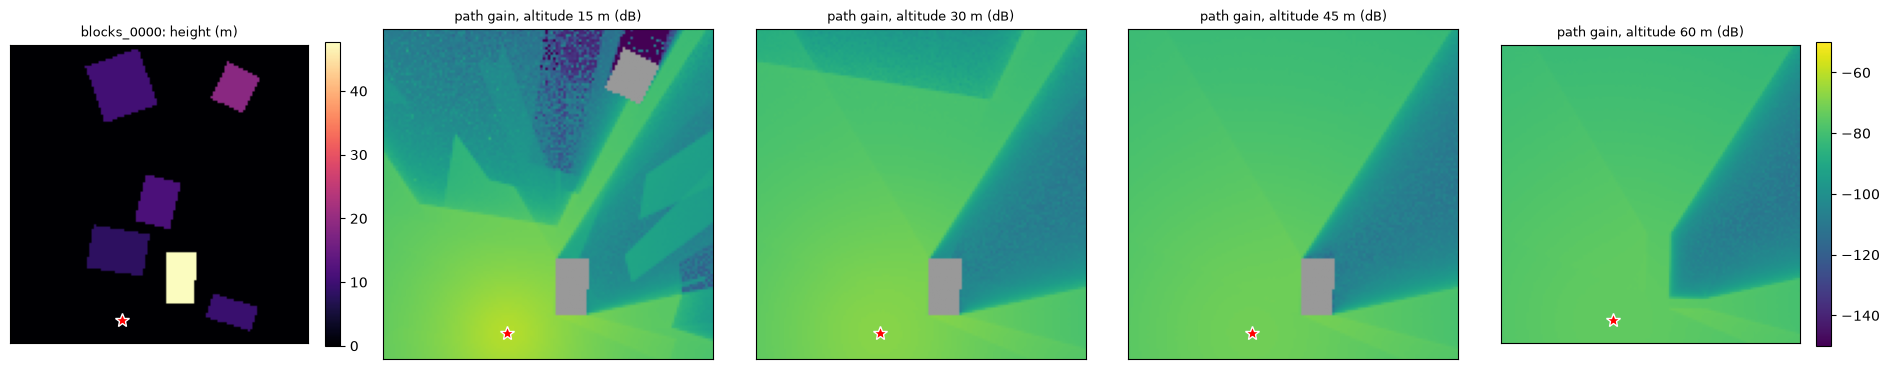

In [6]:
def show_map(ax, img, valid=None, title="", vmin=None, vmax=None, cmap="viridis", station=None):
    img = np.asarray(img, dtype=float).copy()
    if valid is not None:
        img = np.ma.masked_where(~np.asarray(valid), img)
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad("0.6")                       # cells inside buildings (not valid) in grey
    # cell [i, j] has its centre at x = j - 63.5, y = i - 63.5: rows run along y, so origin="lower" puts +y up
    n = img.shape[0]
    im = ax.imshow(img, origin="lower", cmap=cm, vmin=vmin, vmax=vmax,
                   extent=(-n / 2, n / 2, -n / 2, n / 2))
    if station is not None:
        station = np.asarray(station, dtype=float)
        ax.plot(station[0], station[1], "r*", ms=10, mec="w")
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]), ax.set_yticks([])
    return im


# one scene: the 4 altitudes of its first station (the maps of a scene are stored station by station, altitudes increasing)
k0 = 0
ks = [k0 + a for a in range(4)]
h, st, alt, tgt = train_set.batch(ks, "cpu")
fig, axes = plt.subplots(1, 5, figsize=(19, 4))
im = show_map(axes[0], h[0], title=f"{train_set.scene_names[int(train_set.scene_idx[k0])]}: height (m)",
              cmap="magma", station=st[0])
plt.colorbar(im, ax=axes[0], fraction=0.046)
for a in range(4):
    im = show_map(axes[a + 1], tgt[a], h[a] < alt[a] - 0.5, f"path gain, altitude {alt[a]:.0f} m (dB)",
                  CFG["floor_db"], CFG["max_db"], station=st[a])
plt.colorbar(im, ax=axes[-1], fraction=0.046)
plt.tight_layout()
plt.show()

## 3. Model inputs and target
The network receives 7 channels of 128 × 128 cells (8 with the line-of-sight channel of study 3), built on the GPU
for every batch:

| channel | meaning |
|---|---|
| `height` | surface height / 60 m |
| `rel_height` | (altitude − height) / 60 m: clearance between the drone plane and the surface |
| `valid` | 1 where the drone can be |
| `tx` | Gaussian marker (σ = 1 cell) at the station position |
| `fspl` | free space path gain from the station to each cell of the drone plane, 20 log10(λ / 4πd), on the target scale |
| `tx_z`, `altitude` | constant planes with the station height and the altitude / 60 m |
| `los` (study 3 only) | 1 where the straight segment from the station to the cell of the drone plane passes above every building and the terrain (line of sight), else 0 |
| `los_edge` (study 3 only) | edge strength of the `los` map (Sobel filter): the borders between visible and hidden cells |
| `height_edge` (study 3 only) | edge strength of the height map / 60 m (Sobel filter): the walls and roof edges of the buildings |
| `clearance` (study 3 only) | continuous line of sight: smallest height of the station-to-cell segment above the surface / 60 m, limited to [−1, 1]; positive in line of sight, negative behind a building (the deeper in the shadow, the more negative) |

**Target.** Path gain mapped linearly to [0, 1]: −150 dB → 0 and −50 dB → 1 (0.01 = 1 dB).

**Augmentation.** The antennas are isotropic and vertically polarised and the materials isotropic, so propagation
is unchanged by a rotation about the vertical axis or a mirror in a vertical plane. Each training sample receives one
of the 8 symmetries of the square, applied jointly to the inputs, the target and the mask.

In [58]:
WAVELENGTH = 299_792_458.0 / CFG["freq_hz"]


def db_to_unit(db, cfg=CFG):
    return (db - cfg["floor_db"]) / (cfg["max_db"] - cfg["floor_db"])


def unit_to_db(u, cfg=CFG):
    return u * (cfg["max_db"] - cfg["floor_db"]) + cfg["floor_db"]


def free_space_gain_db(d):
    return 20.0 * torch.log10(WAVELENGTH / (4.0 * math.pi * d))


def plane_geometry(heights, station, altitude):
    """dx, dy (B,H,W) from the station to every cell centre, and the 3D distance to the drone plane."""
    B, H, W = heights.shape
    dev = heights.device
    xs = torch.arange(W, device=dev, dtype=torch.float32) - (W - 1) / 2     # x of column j = j - 63.5
    ys = torch.arange(H, device=dev, dtype=torch.float32) - (H - 1) / 2     # y of row i    = i - 63.5
    dx = xs.view(1, 1, W) - station[:, 0].view(B, 1, 1)
    dy = ys.view(1, H, 1) - station[:, 1].view(B, 1, 1)
    dz = (altitude - station[:, 2]).view(B, 1, 1)
    d3 = torch.sqrt(dx ** 2 + dy ** 2 + dz ** 2).clamp_min(1.0)
    return dx.expand(B, H, W), dy.expand(B, H, W), d3


def los_clearance(heights, station, altitude, cfg=CFG):
    """Clearance (m) of every cell: smallest height above the surface of the segment from the station to the centre of
    the cell at the drone altitude (> 0: line of sight). The surface height is read (bilinear) at los_samples points
    along each segment."""
    B, H, W = heights.shape
    dev = heights.device
    t = torch.linspace(0, 1, cfg["los_samples"] + 2, device=dev)[1:-1].view(1, -1, 1, 1)     # (1, K, 1, 1)
    xs = (torch.arange(W, device=dev, dtype=torch.float32) - (W - 1) / 2).view(1, 1, 1, W)
    ys = (torch.arange(H, device=dev, dtype=torch.float32) - (H - 1) / 2).view(1, 1, H, 1)
    sx, sy, sz = (station[:, k].view(B, 1, 1, 1) for k in range(3))
    px = sx + t * (xs - sx)                                                 # (B, K, 1, W)
    py = sy + t * (ys - sy)                                                 # (B, K, H, 1)
    pz = sz + t * (altitude.view(B, 1, 1, 1) - sz)                         # (B, K, 1, 1)
    grid = torch.stack(torch.broadcast_tensors(px / (W / 2), py / (H / 2)), dim=-1)    # (B, K, H, W, 2) in [-1, 1]
    K = t.shape[1]
    surface = F.grid_sample(heights[:, None], grid.view(B, K * H, W, 2), mode="bilinear", padding_mode="border",
                            align_corners=False).view(B, K, H, W)
    return (pz - surface).amin(dim=1)


def line_of_sight(heights, station, altitude, cfg=CFG):
    """1 where the segment from the station to the cell stays above the surface (clearance > 0), else 0."""
    return (los_clearance(heights, station, altitude, cfg) > 0).float()


SOBEL_KERNELS = torch.stack([torch.tensor([[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]]) / 8.0,
                             torch.tensor([[-1.0, -2.0, -1.0], [0.0, 0.0, 0.0], [1.0, 2.0, 1.0]]) / 8.0])[:, None]


def edge_magnitude(img):
    """Edge strength of a (B, H, W) map: magnitude of its Sobel derivatives (3 x 3 convolution, borders replicated)."""
    g = F.conv2d(F.pad(img[:, None], (1, 1, 1, 1), mode="replicate"), SOBEL_KERNELS.to(img))
    return torch.sqrt(g[:, 0] ** 2 + g[:, 1] ** 2)


def make_inputs(heights, station, altitude, cfg=CFG):
    """Model input (B, C, H, W) and validity mask (B, H, W) for one batch."""
    B, H, W = heights.shape
    dx, dy, d3 = plane_geometry(heights, station, altitude)
    alt = altitude.view(B, 1, 1)
    valid = heights < alt - 0.5
    hs = cfg["height_scale"]
    cache = {}

    def clearance_m():                                                 # computed once, even if several channels use it
        if "clearance" not in cache:
            cache["clearance"] = los_clearance(heights, station, altitude, cfg)
        return cache["clearance"]

    def los_map():
        return (clearance_m() > 0).float()

    channels = dict(
        height=lambda: heights / hs,
        rel_height=lambda: (alt - heights) / hs,
        valid=lambda: valid.float(),
        tx=lambda: torch.exp(-(dx ** 2 + dy ** 2) / (2 * cfg["tx_sigma"] ** 2)),
        fspl=lambda: db_to_unit(free_space_gain_db(d3), cfg),
        tx_z=lambda: (station[:, 2] / hs).view(B, 1, 1).expand(B, H, W),
        altitude=lambda: (alt / hs).expand(B, H, W),
        los=lambda: los_map(),
        los_edge=lambda: edge_magnitude(los_map()),
        height_edge=lambda: edge_magnitude(heights / hs),
        clearance=lambda: (clearance_m() / hs).clamp(-1.0, 1.0),
    )
    x = torch.stack([channels[c]() for c in cfg["in_channels"]], dim=1)
    return x, valid


def augment_d4(*tensors):
    """Apply the same random rotation (k * 90 deg) and optional mirror to every sample of each (B, ..., H, W) tensor."""
    B = tensors[0].shape[0]
    ks = torch.randint(0, 4, (B,)).tolist()
    flips = torch.randint(0, 2, (B,)).tolist()
    out = [t.clone() for t in tensors]
    for b in range(B):
        for o, t in zip(out, tensors):
            v = t[b].flip(-1) if flips[b] else t[b]
            o[b] = torch.rot90(v, ks[b], dims=(-2, -1))
    return out


def prepare_batch(heights, station, altitude, target_db, augment=False, cfg=CFG):
    x, valid = make_inputs(heights, station, altitude, cfg)
    y = db_to_unit(target_db.clamp_min(cfg["floor_db"]), cfg)
    if augment:
        x, y, valid = augment_d4(x, y, valid)
    return x, y, valid

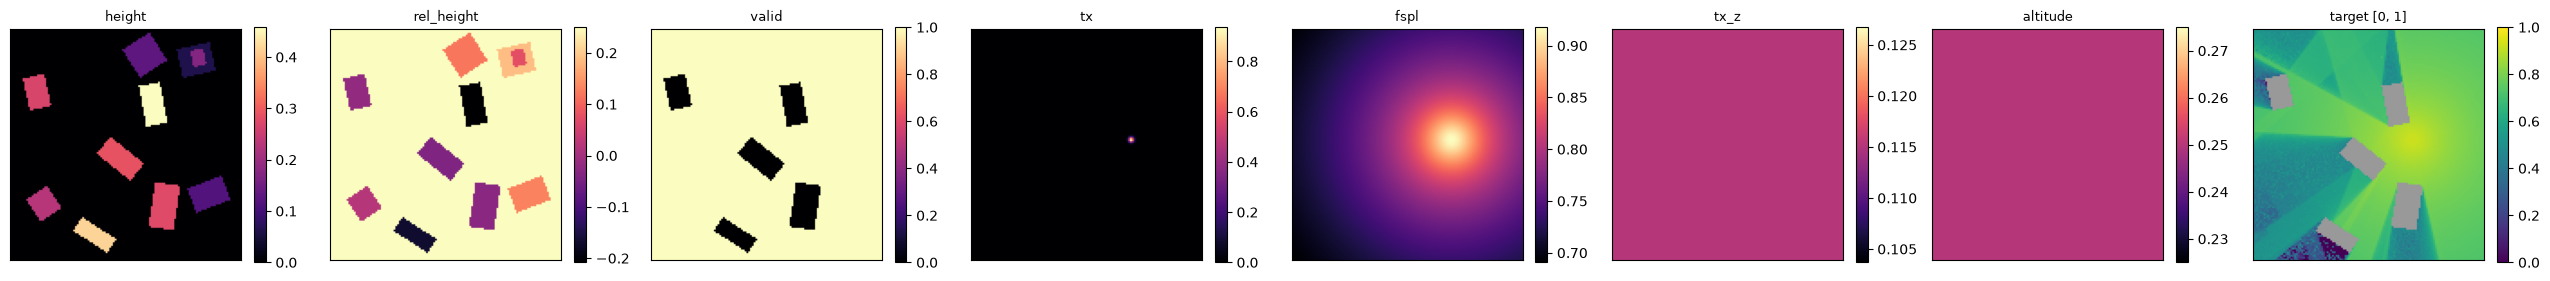

In [8]:
# the input channels of one map
h, st, alt, tgt = val_set.batch([0], DEVICE)
x, valid = make_inputs(h, st, alt)
fig, axes = plt.subplots(1, len(CFG["in_channels"]) + 1, figsize=(3.2 * (len(CFG["in_channels"]) + 1), 3.4))
for ax, name, img in zip(axes, CFG["in_channels"], x[0].cpu()):
    im = show_map(ax, img, title=name, cmap="magma")
    plt.colorbar(im, ax=ax, fraction=0.046)
im = show_map(axes[-1], db_to_unit(tgt[0].clamp_min(CFG["floor_db"])).cpu(), valid[0].cpu(), "target [0, 1]", 0, 1)
plt.colorbar(im, ax=axes[-1], fraction=0.046)
plt.tight_layout()
plt.show()

## 4. Model: RMTransformer
CNN stem → 4 MaxViT stages (MBConv, block attention, grid attention; each stage halves the resolution and doubles the
channels) → CNN decoder of 4 `ConvTranspose2d` blocks with concatenated skip connections → convolutional output head.
Block attention works inside 8 × 8 windows (local), grid attention across an 8 × 8 grid spread over the whole
feature map (global), so every stage has a global receptive field.

Three sizes are defined. They differ only in the number of channels; the studies of this notebook use `tiny`, the
smallest:

| size | stem | stage channels |
|---|---|---|
| `tiny` | 32 | 32, 64, 128, 256 |
| `small` | 64 | 64, 128, 256, 512 |
| `paper` | 128 | 128, 256, 512, 1024 (configuration of the RMTransformer paper) |

In [9]:
def drop_path(x, p, training):
    """Stochastic depth: drop the residual branch of whole samples."""
    if p == 0.0 or not training:
        return x
    keep = 1.0 - p
    mask = x.new_empty((x.shape[0],) + (1,) * (x.ndim - 1)).bernoulli_(keep)
    return x * mask / keep


class DropPath(nn.Module):
    def __init__(self, p=0.0):
        super().__init__()
        self.p = p

    def forward(self, x):
        return drop_path(x, self.p, self.training)


def conv_bn_act(cin, cout, k=3, stride=1):
    return nn.Sequential(nn.Conv2d(cin, cout, k, stride, k // 2, bias=False), nn.BatchNorm2d(cout), nn.GELU())


class SqueezeExcite(nn.Module):
    def __init__(self, ch, reduced):
        super().__init__()
        self.fc1 = nn.Conv2d(ch, reduced, 1)
        self.fc2 = nn.Conv2d(reduced, ch, 1)

    def forward(self, x):
        s = x.mean((2, 3), keepdim=True)
        return x * torch.sigmoid(self.fc2(F.silu(self.fc1(s))))


class MBConv(nn.Module):
    """MaxViT's inverted residual: pre-norm, 1x1 expand, 3x3 depthwise (stride s), SE, 1x1 project, residual."""

    def __init__(self, cin, cout, stride=1, expand=4, se_ratio=0.25, drop_path=0.0):
        super().__init__()
        hid = cout * expand
        self.norm = nn.BatchNorm2d(cin)
        self.expand = nn.Sequential(nn.Conv2d(cin, hid, 1, bias=False), nn.BatchNorm2d(hid), nn.GELU())
        self.dw = nn.Sequential(nn.Conv2d(hid, hid, 3, stride, 1, groups=hid, bias=False), nn.BatchNorm2d(hid),
                                nn.GELU())
        self.se = SqueezeExcite(hid, max(8, int(cout * se_ratio)))
        self.project = nn.Conv2d(hid, cout, 1)
        if stride == 1 and cin == cout:
            self.shortcut = nn.Identity()
        else:
            self.shortcut = nn.Sequential(nn.AvgPool2d(stride) if stride > 1 else nn.Identity(), nn.Conv2d(cin, cout, 1))
        self.drop_path = DropPath(drop_path)

    def forward(self, x):
        return self.shortcut(x) + self.drop_path(self.project(self.se(self.dw(self.expand(self.norm(x))))))


class RelPosAttention(nn.Module):
    """Multi-head self-attention over the size x size tokens of one partition, with a learned relative position bias."""

    def __init__(self, dim, size, head_dim=32):
        super().__init__()
        assert dim % head_dim == 0, f"dim {dim} is not a multiple of head_dim {head_dim}"
        self.heads, self.head_dim = dim // head_dim, head_dim
        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)
        self.rel_bias = nn.Parameter(torch.zeros(self.heads, (2 * size - 1) ** 2))
        nn.init.trunc_normal_(self.rel_bias, std=0.02)
        c = torch.stack(torch.meshgrid(torch.arange(size), torch.arange(size), indexing="ij")).flatten(1)  # 2, N
        rel = c[:, :, None] - c[:, None, :] + size - 1                                                    # 2, N, N
        self.register_buffer("rel_index", rel[0] * (2 * size - 1) + rel[1], persistent=False)

    def forward(self, x):                                     # (B', N, C)
        Bp, N, C = x.shape
        q, k, v = self.qkv(x).view(Bp, N, 3, self.heads, self.head_dim).permute(2, 0, 3, 1, 4).unbind(0)
        bias = self.rel_bias[:, self.rel_index].unsqueeze(0).to(q.dtype)    # 1, heads, N, N
        x = F.scaled_dot_product_attention(q, k, v, attn_mask=bias)
        return self.proj(x.transpose(1, 2).reshape(Bp, N, C))


def window_partition(x, p):          # (B,H,W,C) -> (B*H/p*W/p, p*p, C): local p x p windows
    B, H, W, C = x.shape
    return x.view(B, H // p, p, W // p, p, C).permute(0, 1, 3, 2, 4, 5).reshape(-1, p * p, C)


def window_reverse(t, p, B, H, W):
    return t.view(B, H // p, W // p, p, p, -1).permute(0, 1, 3, 2, 4, 5).reshape(B, H, W, -1)


def grid_partition(x, g):            # (B,H,W,C) -> (B*H/g*W/g, g*g, C): g x g cells spaced H/g apart
    B, H, W, C = x.shape
    return x.view(B, g, H // g, g, W // g, C).permute(0, 2, 4, 1, 3, 5).reshape(-1, g * g, C)


def grid_reverse(t, g, B, H, W):
    return t.view(B, H // g, W // g, g, g, -1).permute(0, 3, 1, 4, 2, 5).reshape(B, H, W, -1)


class PartitionAttention(nn.Module):
    """Pre-norm transformer layer (attention + MLP) on local windows ("block") or on a sparse global grid ("grid")."""

    def __init__(self, dim, mode, size, head_dim=32, mlp_ratio=4, drop_path=0.0):
        super().__init__()
        assert mode in ("block", "grid")
        self.mode, self.size = mode, size
        self.norm1 = nn.LayerNorm(dim)
        self.attn = RelPosAttention(dim, size, head_dim)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, dim * mlp_ratio), nn.GELU(), nn.Linear(dim * mlp_ratio, dim))
        self.drop_path = DropPath(drop_path)

    def forward(self, x):                                     # (B, H, W, C)
        B, H, W, _ = x.shape
        s = self.size
        assert H % s == 0 and W % s == 0, f"feature map {H}x{W} is not divisible by the window / grid size {s}"
        part, rev = (window_partition, window_reverse) if self.mode == "block" else (grid_partition, grid_reverse)
        x = x + self.drop_path(rev(self.attn(part(self.norm1(x), s)), s, B, H, W))
        return x + self.drop_path(self.mlp(self.norm2(x)))


class MaxViTBlock(nn.Module):
    """MBConv -> block attention -> grid attention."""

    def __init__(self, cin, cout, stride, window, head_dim, expand, drop_path):
        super().__init__()
        self.mbconv = MBConv(cin, cout, stride, expand, drop_path=drop_path)
        self.block_attn = PartitionAttention(cout, "block", window, head_dim, drop_path=drop_path)
        self.grid_attn = PartitionAttention(cout, "grid", window, head_dim, drop_path=drop_path)

    def forward(self, x):
        x = self.mbconv(x).permute(0, 2, 3, 1)                # channels last for the attention layers
        x = self.grid_attn(self.block_attn(x))
        return x.permute(0, 3, 1, 2).contiguous()


class DecoderBlock(nn.Module):
    """ConvTranspose2d x2 upsampling, concatenation with the encoder skip (Eq. 6 of the paper), two 3x3 convs."""

    def __init__(self, cin, cskip, cout):
        super().__init__()
        self.up = nn.ConvTranspose2d(cin, cout, 2, stride=2)
        self.fuse = nn.Sequential(conv_bn_act(cout + cskip, cout), conv_bn_act(cout, cout))

    def forward(self, x, skip):
        return self.fuse(torch.cat([self.up(x), skip], dim=1))


class RMTransformer(nn.Module):
    """CNN stem -> 4 MaxViT stages (each /2) -> 4 ConvTranspose2d decoder blocks with skips -> conv head.
    out_ch = 1: path gain map. out_ch = 2: path gain map and signal / no-signal logit map (section 10)."""

    def __init__(self, in_ch, stem_dim=128, dims=(128, 256, 512, 1024), depths=(1, 1, 1, 1), window=8, head_dim=32,
                 mbconv_expand=4, drop_path=0.1, out_ch=1):
        super().__init__()
        self.out_ch = out_ch
        self.stem = nn.Sequential(conv_bn_act(in_ch, stem_dim), conv_bn_act(stem_dim, stem_dim))
        rates = torch.linspace(0, drop_path, sum(depths)).tolist()
        self.stages, cin, r = nn.ModuleList(), stem_dim, 0
        for dim, depth in zip(dims, depths):
            blocks = []
            for i in range(depth):
                blocks.append(MaxViTBlock(cin if i == 0 else dim, dim, 2 if i == 0 else 1, window, head_dim,
                                          mbconv_expand, rates[r]))
                r += 1
            self.stages.append(nn.Sequential(*blocks))
            cin = dim
        skips = [stem_dim, *dims[:-1]]                        # channels of s0, s1, s2, s3
        self.decoder, c = nn.ModuleList(), dims[-1]
        for cs in reversed(skips):
            self.decoder.append(DecoderBlock(c, cs, cs))
            c = cs
        self.head = nn.Sequential(conv_bn_act(c, c // 2), nn.Conv2d(c // 2, out_ch, 1))
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, x):
        feats = [self.stem(x)]
        for stage in self.stages:
            feats.append(stage(feats[-1]))
        y = feats[-1]
        for block, skip in zip(self.decoder, reversed(feats[:-1])):
            y = block(y, skip)
        out = self.head(y)
        return out.squeeze(1) if self.out_ch == 1 else out    # (B, H, W) path gain on the [0, 1] scale, or (B, 2, H, W)

In [10]:
def build_model_kwargs(cfg):
    """Constructor arguments of the RMTransformer for the size and inputs in cfg."""
    return dict(in_ch=len(cfg["in_channels"]), **MODEL_PRESETS[cfg["model_size"]], window=cfg["window"],
                head_dim=cfg["head_dim"], mbconv_expand=cfg["mbconv_expand"], drop_path=cfg["drop_path"],
                out_ch=2 if cfg.get("floor_method", "none") == "two_output" else 1)


import pandas as pd

sizes = []
for size in MODEL_PRESETS:
    m = RMTransformer(**build_model_kwargs({**CFG, "model_size": size}))
    sizes.append(dict(size=size, parameters_M=sum(p.numel() for p in m.parameters()) / 1e6))
    del m
pd.DataFrame(sizes).set_index("size").round(2)

,parameters_M
size,
tiny,3.68
small,14.62
paper,58.28


## 5. Loss functions and treatment of no-signal cells
Let $\hat y_i$ be the predicted and $y_i$ the ray traced path gain of cell $i$ on the [0, 1] scale,
$e_i = \hat y_i - y_i$ the error, and $\mathcal V$ the set of valid cells of the batch. Every loss is averaged over
$\mathcal V$ only.

| loss | definition | behaviour |
|---|---|---|
| **MSE** | $\frac{1}{\lvert\mathcal V\rvert}\sum_{i\in\mathcal V} e_i^2$ | standard in radio map prediction (RadioUNet, PMNet); minimises the RMSE directly; large errors dominate |
| **L1** | $\frac{1}{\lvert\mathcal V\rvert}\sum_{i\in\mathcal V} \lvert e_i\rvert$ | every dB of error weighs the same; robust to outliers; minimises the MAE |
| **Huber** | $\frac{1}{\lvert\mathcal V\rvert}\sum_{i\in\mathcal V} \ell_\delta(e_i)$, with $\ell_\delta(e)=\tfrac12 e^2$ if $\lvert e\rvert\le\delta$, else $\delta(\lvert e\rvert-\tfrac12\delta)$ | quadratic for small errors, linear for large ones; δ = 0.05 (5 dB) |
| **Combined** | $0.4\,L_1 + 0.1\,L_{MSE} + 0.2\,(1-\mathrm{SSIM}) + 0.3\,L_\nabla$ | pixel accuracy (L1, MSE) plus map structure (SSIM) and sharp edges (gradient); weights from RadioMamba (2025) |

* **SSIM** (structural similarity) compares local means, variances and covariance of the two maps in 11 × 11 Gaussian
  windows (σ = 1.5). Cells inside buildings are replaced by the target in the prediction before the comparison, so
  only valid cells contribute.
* **Per-cell weights.** `masked_loss` accepts an optional weight for every cell, which multiplies the pixel terms
  (L1, MSE, Huber) but not the structural terms (SSIM, gradient). Weights are used only by two treatments of study 2
  (section 10) and by the edge-weighted loss of study 3 (section 12); without them every valid cell counts once.
* **Gradient loss** $L_\nabla$: L1 distance between the Sobel derivatives (along x and y) of the prediction and of
  the target, on the valid cells whose 3 × 3 neighbourhood is entirely valid (building walls are not edges of the
  coverage map).

In [11]:
def masked_mean(values, m):
    """Mean of `values` over the cells where the mask m is 1."""
    return (values * m).sum() / m.sum().clamp_min(1.0)


SOBEL_X = torch.tensor([[-1.0, 0.0, 1.0],
                        [-2.0, 0.0, 2.0],
                        [-1.0, 0.0, 1.0]]) / 8.0


def sobel(img):
    """Derivatives of a (B, H, W) map along x and y (Sobel filter, borders replicated)."""
    k = torch.stack([SOBEL_X, SOBEL_X.T])[:, None].to(img)                    # (2, 1, 3, 3)
    g = F.conv2d(F.pad(img[:, None], (1, 1, 1, 1), mode="replicate"), k)      # (B, 2, H, W)
    return g[:, 0], g[:, 1]


def gaussian_window(size=11, sigma=1.5, device=None):
    ax = torch.arange(size, dtype=torch.float32, device=device) - (size - 1) / 2
    g = torch.exp(-ax ** 2 / (2 * sigma ** 2))
    g = g / g.sum()
    return (g[:, None] * g[None, :])[None, None]                              # (1, 1, size, size)


def ssim_map(x, y, size=11, sigma=1.5, data_range=1.0):
    """Local SSIM of every cell of two (B, H, W) maps."""
    w = gaussian_window(size, sigma, x.device)
    pad = size // 2
    blur = lambda t: F.conv2d(F.pad(t[:, None], (pad, pad, pad, pad), mode="replicate"), w)[:, 0]
    mu_x, mu_y = blur(x), blur(y)
    var_x = blur(x * x) - mu_x ** 2
    var_y = blur(y * y) - mu_y ** 2
    cov = blur(x * y) - mu_x * mu_y
    c1, c2 = (0.01 * data_range) ** 2, (0.03 * data_range) ** 2
    return ((2 * mu_x * mu_y + c1) * (2 * cov + c2)) / ((mu_x ** 2 + mu_y ** 2 + c1) * (var_x + var_y + c2))


def masked_loss(pred, y, valid, cfg=CFG, weight=None):
    """Training loss over the valid cells. pred and y: (B, H, W) path gain on the [0, 1] scale.
    weight: optional (B, H, W) weight of every cell for the pixel terms (L1, MSE, Huber)."""
    m = valid.float()
    pixel_mean = lambda values: masked_mean(values if weight is None else values * weight, m)
    kind = cfg["loss"]
    if kind == "mse":
        return pixel_mean((pred - y) ** 2)
    if kind == "l1":
        return pixel_mean((pred - y).abs())
    if kind == "huber":
        return pixel_mean(F.huber_loss(pred, y, reduction="none", delta=cfg["huber_delta"]))
    if kind == "combo":
        w = cfg["loss_weights"]
        total = pred.new_zeros(())
        if w.get("l1", 0):
            total = total + w["l1"] * pixel_mean((pred - y).abs())
        if w.get("mse", 0):
            total = total + w["mse"] * pixel_mean((pred - y) ** 2)
        if w.get("ssim", 0):
            filled = torch.where(valid, pred, y)
            total = total + w["ssim"] * masked_mean(1.0 - ssim_map(filled, y), m)
        if w.get("grad", 0):
            inner = -F.max_pool2d(-m[:, None], 3, 1, 1)[:, 0]
            gx_p, gy_p = sobel(pred)
            gx_t, gy_t = sobel(y)
            total = total + w["grad"] * masked_mean((gx_p - gx_t).abs() + (gy_p - gy_t).abs(), inner)
        return total
    raise ValueError(f"unknown loss {kind!r}")

### 5.1 Treatment of no-signal cells
Cells that no ray reached are stored at −150 dB (0 on the [0, 1] scale). `training_loss` applies the treatment
selected by `floor_method` (of the no-signal cells, or of all weak-signal cells) before computing the loss above; the treatments are motivated in section 9 and described
in section 10. With `floor_method="none"` (study 1) no-signal cells are ordinary targets at −150 dB.

In [12]:
def no_signal(y, cfg=CFG):
    """Cells whose target is at the floor (-150 dB): no ray reached them."""
    return y <= db_to_unit(cfg["floor_db"] + 1e-3, cfg)


def combine(*weights):
    """Product of the per-cell weights that are not None (None when there is none)."""
    weights = [w for w in weights if w is not None]
    out = None
    for w in weights:
        out = w if out is None else out * w
    return out


def training_loss(out, y, valid, cfg=CFG):
    """Loss of one batch with the selected treatment of no-signal cells and the optional edge weighting (5.2).
    y: target on the [0, 1] scale."""
    method = cfg.get("floor_method", "none")
    tau = db_to_unit(cfg["floor_threshold_db"], cfg)                  # -130 dB on the [0, 1] scale
    edge_w = edge_weight_map(y, valid, cfg)                           # None unless edge_weight != 1
    if method == "none":
        return masked_loss(out, y, valid, cfg, edge_w)
    if method == "truncate":                                          # every target below tau becomes tau
        return masked_loss(out, y.clamp_min(tau), valid, cfg, edge_w)
    if method == "censor":                                            # no-signal cell: target "any value <= tau"
        target = torch.where(no_signal(y, cfg), torch.clamp(out.detach(), max=tau), y)
        return masked_loss(out, target, valid, cfg, edge_w)
    if method == "two_output":                                        # out[:, 0]: path gain, out[:, 1]: signal logit
        gain, logit = out[:, 0], out[:, 1]
        silent = no_signal(y, cfg)
        gain_loss = masked_loss(gain, torch.where(silent, gain.detach(), y), valid, cfg, edge_w)   # signal cells only
        signal_loss = masked_mean(F.binary_cross_entropy_with_logits(logit, (~silent).float(), reduction="none"),
                                  valid.float())
        return gain_loss + cfg["signal_loss_weight"] * signal_loss
    if method == "asymmetric":                                        # overestimating a weak signal costs more
        weak = y < db_to_unit(cfg["weak_db"], cfg)
        over = out.detach() > y
        weight = 1.0 + (cfg["asym_factor"] - 1.0) * (weak & over).float()
        return masked_loss(out, y, valid, cfg, combine(weight, edge_w))
    if method == "reweight":                                          # rare path gain values count more
        table = torch.as_tensor(cfg["reweight_table"], dtype=torch.float32, device=y.device)
        bins = (y * (cfg["max_db"] - cfg["floor_db"]) / cfg["reweight_bin_db"]).long().clamp(0, len(table) - 1)
        return masked_loss(out, y, valid, cfg, combine(table[bins], edge_w))
    raise ValueError(f"unknown floor_method {method!r}")


def reweight_table(split, cfg=CFG, n_maps=2000, smoothing_bins=1.0, power=0.5, max_weight=10.0):
    """Weight of every path gain bin from the training data, by label distribution smoothing (Yang et al., 2021):
    the frequency of each bin is smoothed with a Gaussian kernel, the weight is (smoothed frequency)^-power,
    normalised to a mean of 1 over the valid cells and capped at max_weight."""
    k = torch.as_tensor(np.linspace(0, len(split) - 1, min(n_maps, len(split))).astype(int))
    h = split.heights[split.scene_idx[k]]
    valid = h < split.altitude[k].view(-1, 1, 1) - 0.5
    gain = split.target[k].clamp_min(cfg["floor_db"])[valid].numpy()
    bin_db = cfg["reweight_bin_db"]
    n_bins = int(np.ceil((cfg["max_db"] - cfg["floor_db"]) / bin_db))
    counts = np.bincount(np.clip(((gain - cfg["floor_db"]) // bin_db).astype(int), 0, n_bins - 1),
                         minlength=n_bins).astype(float)
    kernel = np.exp(-0.5 * (np.arange(-3, 4) / smoothing_bins) ** 2)
    smoothed = np.convolve(counts, kernel / kernel.sum(), mode="same")
    weights = np.clip(smoothed, 1.0, None) ** -power
    weights = np.minimum(weights * counts.sum() / (weights * counts).sum(), max_weight)
    lower = cfg["floor_db"] + bin_db * np.arange(n_bins)
    return pd.DataFrame({"bin (dB)": [f"{a:g} to {a + bin_db:g}" for a in lower],
                         "share of valid cells (%)": 100 * counts / counts.sum(), "weight": weights})

### 5.2 Edges of the coverage map
An **edge** is a cell where the ray traced map changes by at least 3 dB per cell (magnitude of the Sobel derivative),
computed after clipping the map at −130 dB so that the no-signal cells do not create edges, and ignoring the walls of
buildings (only cells whose 8 neighbours are valid can be edges). Cells within 2 cells of an edge are **near an
edge**. With `edge_weight` > 1 (study 3, section 12) their errors count `edge_weight` times in the pixel terms of the
loss, as in the border weight maps of U-Net and the edge-weighted losses of image restoration.

In [13]:
def near_edges(gain_db, valid, cfg=CFG):
    """Valid cells within edge_width cells of a sharp change (>= edge_threshold_db per cell) of a (B, H, W) path gain
    map in dB. The map is clipped at floor_threshold_db first, so the no-signal cells do not create edges."""
    gx, gy = sobel(gain_db.clamp_min(cfg["floor_threshold_db"]))
    inner = -F.max_pool2d(-valid.float()[:, None], 3, 1, 1)[:, 0] > 0           # valid cells with 8 valid neighbours
    edge = inner & (torch.sqrt(gx ** 2 + gy ** 2) >= cfg["edge_threshold_db"])
    w = cfg["edge_width"]
    return valid & (F.max_pool2d(edge.float()[:, None], 2 * w + 1, 1, w)[:, 0] > 0)


def edge_weight_map(y, valid, cfg=CFG):
    """Per-cell weight of the edge-weighted loss (None when edge_weight is 1). y: target on the [0, 1] scale."""
    if cfg.get("edge_weight", 1.0) == 1.0:
        return None
    near = near_edges(unit_to_db(y, cfg), valid, cfg)
    return 1.0 + (cfg["edge_weight"] - 1.0) * near.float()

## 6. Evaluation metrics
All metrics are computed in dB on the valid cells, after clipping the prediction to [−150, −50] dB, with the
checkpoint selected on `val`. They do not depend on the training loss, so every experiment is measured in the same way.

| metric | definition |
|---|---|
| `rmse_db` | RMSE of each map, averaged over the maps (main metric) |
| `rmse_db_pooled` | RMSE over all valid cells of the split |
| `mae_db`, `bias_db` | mean absolute error and mean signed error (prediction − ray tracing) |
| `rmse_signal_db` | RMSE over the cells that receive a signal (target > −150 dB) |
| `cov_err@T` | share of valid cells where prediction and ray tracing disagree on path gain ≥ T (coverage prediction error, Eq. 7 of the RMTransformer paper), for T = −80, −100, −110 dB |
| `boundary_rmse@T` | RMSE over the cells within 2 cells of the true coverage boundary at T |
| `rmse_link_db` | RMSE per map after clipping prediction and ray tracing at −130 dB, averaged over the maps: differences between values that are all too weak for a link are ignored (section 10) |
| `no_signal_false_link` | share of no-signal cells predicted at ≥ −110 dB: a link is predicted where the ray tracer finds no signal |
| `no_signal_detected` | share of no-signal cells predicted at ≤ −130 dB |
| `edge_rmse_db` | RMSE over the cells near an edge of the ray traced map (section 5.2), prediction and ray tracing clipped at −130 dB |
| `non_edge_rmse_db` | the same over all other valid cells |

A **free space** reference (path gain without any building) is reported alongside the models.

In [14]:
def amp_autocast(cfg=CFG):
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=cfg["amp"] and DEVICE.type == "cuda")


def model_predictor(model, cfg=CFG):
    """predict(heights, station, altitude) -> path gain in dB (B, H, W)."""
    method = cfg.get("floor_method", "none")
    low = db_to_unit(cfg["floor_threshold_db"], cfg) if method == "truncate" else 0.0

    @torch.no_grad()
    def predict(heights, station, altitude):
        x, _ = make_inputs(heights, station, altitude, cfg)
        with amp_autocast(cfg):
            out = model(x).float()
        if method == "two_output":                                    # P(signal) < 0.5  ->  -150 dB
            gain = torch.where(out[:, 1] >= 0, out[:, 0].clamp(0.0, 1.0), torch.zeros_like(out[:, 0]))
        else:
            gain = out.clamp(low, 1.0)
        return unit_to_db(gain, cfg)
    return predict


def free_space_predictor(cfg=CFG):
    """Baseline: free space path gain everywhere (no buildings)."""
    @torch.no_grad()
    def predict(heights, station, altitude):
        return free_space_gain_db(plane_geometry(heights, station, altitude)[2]).clamp(cfg["floor_db"], cfg["max_db"])
    return predict


def coverage_boundary(cov, valid, width):
    """Valid cells with both covered and uncovered valid cells within `width` cells (Chebyshev distance)."""
    k = 2 * width + 1
    hi = F.max_pool2d(torch.where(valid, cov, -1.0)[:, None], k, 1, width)[:, 0]      # max over valid neighbours
    lo = -F.max_pool2d(torch.where(valid, -cov, -2.0)[:, None], k, 1, width)[:, 0]    # min over valid neighbours
    return valid & (hi == 1) & (lo == 0)


@torch.no_grad()
def evaluate(predict, split, cfg=CFG, indices=None):
    """Per map error sums and metrics of predict() on the maps `indices` of a split (all maps by default)."""
    idx_all = np.arange(len(split)) if indices is None else np.asarray(indices)
    thr, w = cfg["coverage_thresholds_db"], cfg["boundary_width"]
    link = cfg.get("floor_threshold_db", -130.0)
    acc = {k: [] for k in ("n", "sse", "sae", "se", "n_sig", "sse_sig", "sse_link", "n_nosig", "nosig_link",
                           "nosig_low", "n_edge", "sse_edge")}
    for t in thr:
        acc.update({f"cov_wrong@{t:g}": [], f"bnd_n@{t:g}": [], f"bnd_sse@{t:g}": []})
    for s in range(0, len(idx_all), cfg["eval_batch_size"]):
        h, st, alt, tgt = split.batch(idx_all[s:s + cfg["eval_batch_size"]], DEVICE)
        pred = predict(h, st, alt)
        tgt = tgt.clamp_min(cfg["floor_db"])
        valid = h < alt.view(-1, 1, 1) - 0.5
        m = valid.float()
        err = (pred - tgt) * m
        sig = m * (tgt > cfg["floor_db"] + 1e-3).float()
        acc["n"].append(m.sum((1, 2)))
        acc["sse"].append((err ** 2).sum((1, 2)))
        acc["sae"].append(err.abs().sum((1, 2)))
        acc["se"].append(err.sum((1, 2)))
        acc["n_sig"].append(sig.sum((1, 2)))
        acc["sse_sig"].append((err ** 2 * sig).sum((1, 2)))
        err_link = (pred.clamp_min(link) - tgt.clamp_min(link)) * m
        nosig = m - sig
        acc["sse_link"].append((err_link ** 2).sum((1, 2)))
        acc["n_nosig"].append(nosig.sum((1, 2)))
        acc["nosig_link"].append((nosig * (pred >= thr[-1]).float()).sum((1, 2)))
        acc["nosig_low"].append((nosig * (pred <= link + 0.01).float()).sum((1, 2)))
        near = near_edges(tgt, valid, cfg).float()
        acc["n_edge"].append(near.sum((1, 2)))
        acc["sse_edge"].append((err_link ** 2 * near).sum((1, 2)))
        for t in thr:
            cov_t, cov_p = (tgt >= t).float(), (pred >= t).float()
            band = coverage_boundary(cov_t, valid, w).float()
            acc[f"cov_wrong@{t:g}"].append(((cov_t != cov_p).float() * m).sum((1, 2)))
            acc[f"bnd_n@{t:g}"].append(band.sum((1, 2)))
            acc[f"bnd_sse@{t:g}"].append((err ** 2 * band).sum((1, 2)))
    res = {k: torch.cat(v).double().cpu().numpy() for k, v in acc.items()}
    n = np.maximum(res["n"], 1)
    res.update(idx=idx_all, rmse_db=np.sqrt(res["sse"] / n), mae_db=res["sae"] / n,
               rmse_link_db=np.sqrt(res["sse_link"] / n),
               family=split.family[idx_all], altitude=split.altitude.numpy()[idx_all],
               source=split.source[idx_all], rt_time=split.rt_time[idx_all])
    return res


def summarize(res, cfg=CFG, mask=None):
    """Scalar metrics of an evaluate() result (optionally of the maps where mask is True)."""
    r = res if mask is None else {k: (v[mask] if isinstance(v, np.ndarray) and len(v) == len(mask) else v)
                                  for k, v in res.items()}
    N = r["n"].sum()
    out = dict(maps=len(r["n"]), rmse_db=r["rmse_db"].mean(), rmse_db_pooled=np.sqrt(r["sse"].sum() / N),
               mae_db=r["sae"].sum() / N, bias_db=r["se"].sum() / N,
               rmse_signal_db=np.sqrt(r["sse_sig"].sum() / max(r["n_sig"].sum(), 1)))
    out["nrmse"] = out["rmse_db_pooled"] / (cfg["max_db"] - cfg["floor_db"])
    out["rmse_link_db"] = r["rmse_link_db"].mean()
    n_nosig = max(r["n_nosig"].sum(), 1)
    out["no_signal_false_link"] = r["nosig_link"].sum() / n_nosig
    out["no_signal_detected"] = r["nosig_low"].sum() / n_nosig
    n_edge = r["n_edge"].sum()
    out["edge_rmse_db"] = np.sqrt(r["sse_edge"].sum() / max(n_edge, 1))
    out["non_edge_rmse_db"] = np.sqrt((r["sse_link"].sum() - r["sse_edge"].sum()) / max(N - n_edge, 1))
    for t in cfg["coverage_thresholds_db"]:
        out[f"cov_err@{t:g}"] = r[f"cov_wrong@{t:g}"].sum() / N
        out[f"boundary_rmse@{t:g}"] = np.sqrt(r[f"bnd_sse@{t:g}"].sum() / max(r[f"bnd_n@{t:g}"].sum(), 1))
    return {k: float(v) for k, v in out.items()}

## 7. Training procedure and experiment runner
`train` runs the optimisation described in the protocol and, after every epoch, evaluates on `val`, keeps the best
checkpoint (`best.pt`, lowest validation RMSE; lowest validation `rmse_link_db` in study 2) and the full training state (`last.pt`). `run_experiment` trains one configuration, evaluates
its best checkpoint on `val`, `test` and `ood`, measures its prediction time, and stores everything in
`results.json` in the experiment's folder. A finished experiment is loaded from that file instead of being trained
again.

In [15]:
def make_optimizer(model, cfg=CFG):
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        (no_decay if p.ndim < 2 or "rel_bias" in name else decay).append(p)
    return torch.optim.AdamW([dict(params=decay, weight_decay=cfg["weight_decay"]),
                              dict(params=no_decay, weight_decay=0.0)], lr=cfg["lr"])


def warmup_cosine(total_steps, cfg=CFG):
    lr, min_lr, warm = cfg["lr"], cfg["min_lr"], cfg["warmup_steps"]

    def factor(step):
        if step < warm:
            return (step + 1) / warm
        t = min(1.0, (step - warm) / max(1, total_steps - warm))
        return (min_lr + 0.5 * (lr - min_lr) * (1 + math.cos(math.pi * t))) / lr
    return factor


def train(model, model_kwargs, train_set, val_set, cfg, run_dir, resume=True):
    bs = cfg["batch_size"]
    steps_per_epoch = len(train_set) // bs
    total = steps_per_epoch * cfg["epochs"]
    opt = make_optimizer(model, cfg)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, warmup_cosine(total, cfg))
    scaler = torch.amp.GradScaler("cuda", enabled=cfg["amp"] and DEVICE.type == "cuda" and AMP_DTYPE == torch.float16)
    start, best, history = 0, float("inf"), []
    last, best_path = run_dir / "last.pt", run_dir / "best.pt"
    if resume and last.exists():
        ck = torch.load(last, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"])
        scaler.load_state_dict(ck["scaler"])
        start, best, history = ck["epoch"], ck["best"], ck["history"]
        print(f"resumed from {last} after epoch {start} (best validation {cfg.get('select_metric', 'rmse_db')} "
              f"{best:.3f} dB)")
    (run_dir / "config.json").write_text(json.dumps(dict(cfg=cfg, model_kwargs=model_kwargs), indent=2, default=list))
    val_idx = None if cfg["max_val_maps"] is None else np.linspace(0, len(val_set) - 1, cfg["max_val_maps"]).astype(int)
    span = cfg["max_db"] - cfg["floor_db"]
    print(f"{len(train_set)} training maps, {steps_per_epoch} steps per epoch, {total} steps in total")

    for epoch in range(start, cfg["epochs"]):
        t0 = time.time()
        seed_everything(cfg["seed"] + epoch)                   # same order and augmentation when resuming
        perm = torch.randperm(len(train_set))
        model.train()
        loss_sum = torch.zeros((), device=DEVICE)
        steps = range(steps_per_epoch)
        if tqdm is not None:
            steps = tqdm(steps, desc=f"epoch {epoch + 1}/{cfg['epochs']}", leave=False)
        for b in steps:
            x, y, valid = prepare_batch(*train_set.batch(perm[b * bs:(b + 1) * bs], DEVICE),
                                        augment=cfg["augment"], cfg=cfg)
            with amp_autocast(cfg):
                out = model(x)
            loss = training_loss(out.float(), y, valid, cfg)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"loss is {loss.item()} at epoch {epoch + 1}, step {b}")
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            scaler.step(opt)
            scaler.update()
            sched.step()
            loss_sum += loss.detach()
            if tqdm is not None and b % 50 == 0:
                steps.set_postfix(loss=f"{loss.item():.2e}", lr=f"{sched.get_last_lr()[0]:.1e}")
        train_loss = loss_sum.item() / steps_per_epoch

        model.eval()
        val = summarize(evaluate(model_predictor(model, cfg), val_set, cfg, val_idx), cfg)
        entry = dict(epoch=epoch + 1, train_loss=train_loss, lr=sched.get_last_lr()[0], time_s=time.time() - t0,
                     **{f"val_{k}": v for k, v in val.items() if k != "maps"})
        if cfg["loss"] == "mse":
            entry["train_rmse_db"] = math.sqrt(train_loss) * span   # on augmented training batches, in train mode
        history.append(entry)
        select = cfg.get("select_metric", "rmse_db")
        if val[select] < best:
            best = val[select]
            torch.save(dict(model=model.state_dict(), model_kwargs=model_kwargs, cfg=cfg, epoch=epoch + 1,
                            val=val), best_path)
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        scaler=scaler.state_dict(), epoch=epoch + 1, best=best, history=history,
                        model_kwargs=model_kwargs, cfg=cfg), last)
        (run_dir / "history.json").write_text(json.dumps(history, indent=2))
        t_cov = cfg["coverage_thresholds_db"][-1]
        cov = val[f"cov_err@{t_cov:g}"]
        print(f"epoch {epoch + 1:3d}/{cfg['epochs']} | train loss {train_loss:.3e} | val RMSE {val['rmse_db']:.3f} dB "
              f"(MAE {val['mae_db']:.3f}, cov err@{t_cov:g} {cov:.3%}) | lr {entry['lr']:.1e} | "
              f"{entry['time_s']:.0f} s" + ("  *best*" if val[select] == best else ""))
    return history

In [16]:
EVAL_SPLITS = {"val": val_set, "test": test_set, "ood": ood_set}


def to_json(obj):
    return obj.item() if hasattr(obj, "item") else list(obj)


def group_rmse(res, cfg):
    """RMSE (dB, mean over maps) per city family and per altitude."""
    return dict(family={f: summarize(res, cfg, mask=res["family"] == f)["rmse_db"] for f in np.unique(res["family"])},
                altitude={f"{a:g} m": summarize(res, cfg, mask=res["altitude"] == a)["rmse_db"]
                          for a in np.unique(res["altitude"])})


@torch.no_grad()
def prediction_time_ms(predict, split, batch_sizes=(1, 32), n_iter=30, warmup=5):
    """Milliseconds per map, from inputs on the GPU to the path gain map in dB."""
    out = {}
    for bs in batch_sizes:
        h, st, alt, _ = split.batch(np.arange(bs), DEVICE)
        for _ in range(warmup):
            predict(h, st, alt)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n_iter):
            predict(h, st, alt)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        out[f"batch {bs}"] = 1e3 * (time.perf_counter() - t0) / (n_iter * bs)
    return out


def experiment_name(model_size, loss, floor_method="none"):
    return f"{model_size}_{loss}" + ("" if floor_method == "none" else f"_{floor_method}")


def run_experiment(name, model_size, loss, floor_method="none", **settings):
    """Train (or resume) one configuration, then evaluate its best checkpoint. Returns the results dictionary.
    settings: further CFG entries of this experiment (e.g. reweight_table)."""
    run_dir = STUDY_DIR / name
    result_file = run_dir / "results.json"
    if result_file.exists():
        print(f"{name}: finished earlier, results loaded from {result_file}")
        return json.loads(result_file.read_text())
    run_dir.mkdir(parents=True, exist_ok=True)
    cfg = {**CFG, "model_size": model_size, "loss": loss, "floor_method": floor_method,
           "select_metric": "rmse_db" if floor_method == "none" else "rmse_link_db", **settings}
    model_kwargs = build_model_kwargs(cfg)
    seed_everything(cfg["seed"])                       # same initial weights for every run of the same size
    model = RMTransformer(**model_kwargs).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"=== {name}: model {model_size} ({n_params / 1e6:.2f} M parameters), loss {loss}, "
          f"no-signal cells: {floor_method}")
    history = train(model, model_kwargs, train_set, val_set, cfg, run_dir)

    ck = torch.load(run_dir / "best.pt", map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model"])
    model.eval()
    predict = model_predictor(model, cfg)
    summary, groups = {}, {}
    for split, ds in EVAL_SPLITS.items():
        res = evaluate(predict, ds, cfg)
        summary[split] = summarize(res, cfg)
        groups[split] = group_rmse(res, cfg)
    result = dict(name=name, model_size=model_size, loss=loss, floor_method=floor_method, parameters=n_params,
                  best_epoch=ck["epoch"],
                  train_time_min=sum(h["time_s"] for h in history) / 60,
                  epoch_time_s=float(np.median([h["time_s"] for h in history])),
                  ms_per_map=prediction_time_ms(predict, test_set), summary=summary, groups=groups,
                  history=history, cfg=cfg, model_kwargs=model_kwargs)
    result_file.write_text(json.dumps(result, indent=2, default=to_json))
    del model, predict
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return result


def free_space_reference():
    """Metrics of the free space path gain (no buildings), computed once."""
    f = STUDY_DIR / "free_space.json"
    if f.exists():
        return json.loads(f.read_text())
    summary = {s: summarize(evaluate(free_space_predictor(CFG), ds, CFG), CFG) for s, ds in EVAL_SPLITS.items()}
    result = dict(name="free space", model_size="-", loss="-", parameters=0, summary=summary)
    f.write_text(json.dumps(result, indent=2, default=to_json))
    return result


FREE_SPACE = free_space_reference()

In [17]:
T_REF = CFG["coverage_thresholds_db"][-1]                     # -110 dB: the coverage threshold used in the tables
RT_MS = 1e3 * float(np.median(test_set.rt_time))              # ray tracing time per map (median, test split)


def comparison_table(results, reference=None):
    """One row per experiment: accuracy on val / test / ood and cost."""
    rows = []
    for r in results + ([reference] if reference else []):
        s = r["summary"]
        row = {"model": r["model_size"], "loss": r["loss"],
               "no-signal cells": r.get("floor_method", "none" if "history" in r else "-"),
               "parameters (M)": r["parameters"] / 1e6,
               "val RMSE": s["val"]["rmse_db"], "test RMSE": s["test"]["rmse_db"], "ood RMSE": s["ood"]["rmse_db"],
               "test MAE": s["test"]["mae_db"], "test RMSE signal": s["test"]["rmse_signal_db"],
               f"test boundary RMSE @{T_REF:g}": s["test"][f"boundary_rmse@{T_REF:g}"],
               f"test cov. error @{T_REF:g} (%)": 100 * s["test"][f"cov_err@{T_REF:g}"],
               f"ood cov. error @{T_REF:g} (%)": 100 * s["ood"][f"cov_err@{T_REF:g}"]}
        if "history" in r:
            row.update({"best epoch": r["best_epoch"], "training time (min)": r["train_time_min"]})
        rows.append(pd.Series(row, name=r["name"]))
    return pd.DataFrame(rows)


def group_table(results, group):
    """RMSE (dB) per city family or per altitude, for test and ood."""
    rows = {}
    for r in results:
        rows[r["name"]] = {f"{split} / {k}": v for split in ("test", "ood") for k, v in r["groups"][split][group].items()}
    return pd.DataFrame(rows).T


def plot_validation_curves(results, title):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    for r in results:
        ep = [h["epoch"] for h in r["history"]]
        axes[0].plot(ep, [h["val_rmse_db"] for h in r["history"]], marker="o", ms=3, label=r["name"])
        axes[1].plot(ep, [100 * h[f"val_cov_err@{T_REF:g}"] for h in r["history"]], marker="o", ms=3, label=r["name"])
    axes[0].set_ylabel("validation RMSE (dB)")
    axes[1].set_ylabel(f"validation coverage error @{T_REF:g} dB (%)")
    for ax in axes:
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


@torch.no_grad()
def plot_predictions(results, split, k, title):
    """Ray traced map and the prediction and error map of every experiment, for map k of a split."""
    h, st, alt, tgt = split.batch([k], DEVICE)
    valid = (h < alt.view(-1, 1, 1) - 0.5)[0].cpu().numpy()
    target = tgt.clamp_min(CFG["floor_db"])[0].cpu().numpy()
    n = len(results) + 1
    fig, axes = plt.subplots(2, n, figsize=(3.6 * n, 7.2))
    show_map(axes[0, 0], target, valid, "ray tracing (dB)", CFG["floor_db"], CFG["max_db"], station=st[0].cpu())
    show_map(axes[1, 0], h[0].cpu(), title="height (m)", cmap="magma", station=st[0].cpu())
    for col, r in enumerate(results, start=1):
        model = RMTransformer(**r["model_kwargs"]).to(DEVICE)
        model.load_state_dict(torch.load(STUDY_DIR / r["name"] / "best.pt", map_location=DEVICE,
                                         weights_only=False)["model"])
        model.eval()
        pred = model_predictor(model, r["cfg"])(h, st, alt)[0].cpu().numpy()
        err = pred - target
        rmse = float(np.sqrt(np.mean(err[valid] ** 2)))
        im0 = show_map(axes[0, col], pred, valid, f"{r['name']} (dB)", CFG["floor_db"], CFG["max_db"])
        im1 = show_map(axes[1, col], err, valid, f"error, RMSE {rmse:.2f} dB", -20, 20, cmap="RdBu_r")
        del model
    fig.colorbar(im0, ax=axes[0, :], fraction=0.015, label="path gain (dB)")
    fig.colorbar(im1, ax=axes[1, :], fraction=0.015, label="prediction − ray tracing (dB)")
    name = split.scene_names[int(split.scene_idx[k])]
    fig.suptitle(f"{title}: {split.name} map {k} ({name}, altitude {float(alt[0]):.0f} m)")
    plt.show()


EXAMPLE_TEST = int(np.where(test_set.altitude.numpy() == 15.0)[0][40])
EXAMPLE_OOD = int(np.where(ood_set.altitude.numpy() == 15.0)[0][40])
pd.set_option("display.precision", 3)

## 8. Study 1: training loss
Model `tiny`, identical in every run except for the loss.

### 8.1 Single losses: MSE, L1 and Huber

In [18]:
tiny_mse = run_experiment("tiny_mse", "tiny", "mse")

tiny_mse: finished earlier, results loaded from runs\loss_and_size_study\tiny_mse\results.json


In [19]:
tiny_l1 = run_experiment("tiny_l1", "tiny", "l1")

tiny_l1: finished earlier, results loaded from runs\loss_and_size_study\tiny_l1\results.json


In [20]:
tiny_huber = run_experiment("tiny_huber", "tiny", "huber")

tiny_huber: finished earlier, results loaded from runs\loss_and_size_study\tiny_huber\results.json


### 8.2 Comparison of the single losses
All values in dB unless stated otherwise. The free space row is the reference without any building.

In [21]:
single_losses = [tiny_mse, tiny_l1, tiny_huber]
comparison_table(single_losses, FREE_SPACE)

,model,loss,no-signal cells,parameters (M),val RMSE,test RMSE,ood RMSE,test MAE,test RMSE signal,test boundary RMSE @-110,test cov. error @-110 (%),ood cov. error @-110 (%),best epoch,training time (min)
tiny_mse,tiny,mse,none,3.681,6.487,6.741,7.560,4.565,6.901,11.066,6.418,8.172,20.0,16.596
tiny_l1,tiny,l1,none,3.681,6.354,6.645,7.660,4.266,6.769,10.950,6.327,8.368,18.0,16.355
tiny_huber,tiny,huber,none,3.681,6.352,6.634,7.360,4.308,6.869,11.022,6.367,7.873,20.0,16.156
free space,-,-,-,0.000,17.719,18.653,21.072,13.335,18.634,34.517,13.048,16.924,NaN,NaN


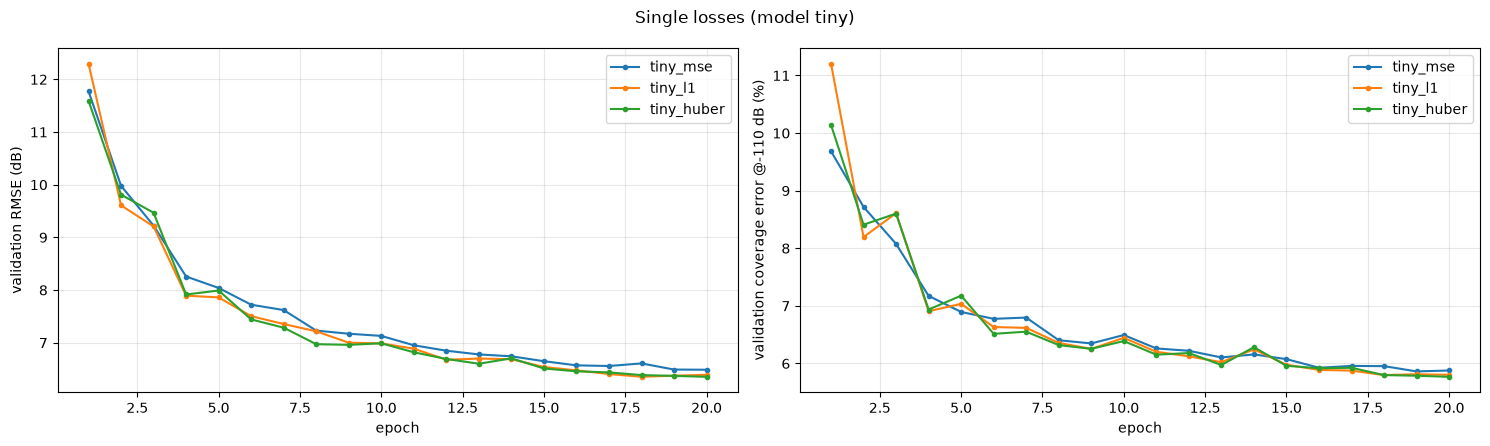

In [22]:
plot_validation_curves(single_losses, "Single losses (model tiny)")

In [23]:
group_table(single_losses, "family")

,test / blocks,test / downtown,test / grid,ood / canyon,ood / courtyard,ood / hilly
tiny_mse,6.211,8.226,5.786,8.991,7.261,6.427
tiny_l1,6.143,8.157,5.633,9.320,7.371,6.290
tiny_huber,6.053,8.177,5.671,8.811,7.016,6.254


#### Observations
* All three losses divide the error by about 2.8 compared with free space (test RMSE 6.6–6.7 dB against 18.7 dB).
* L1 and Huber are slightly more accurate than MSE (validation RMSE 6.35 dB against 6.49 dB) and clearly better in
  MAE (4.06–4.12 dB against 4.37 dB).
* On `ood` Huber is the most accurate (7.36 dB) and L1 the least (7.66 dB); all three overestimate the path gain there
  (bias +1.1 to +1.7 dB).
* The coverage error at −110 dB hardly depends on the loss (test 6.3–6.4 %).
* `downtown` (`test`) and `canyon` (`ood`) are the hardest families for every loss.
* The validation RMSE is still decreasing at epoch 20: training has not converged.

### 8.3 Combined loss
$0.4\,L_1 + 0.1\,L_{MSE} + 0.2\,(1-\mathrm{SSIM}) + 0.3\,L_\nabla$, same model and training as above.

In [24]:
tiny_combo = run_experiment("tiny_combo", "tiny", "combo")

tiny_combo: finished earlier, results loaded from runs\loss_and_size_study\tiny_combo\results.json


### 8.4 Comparison of the four losses

In [25]:
loss_results = [tiny_mse, tiny_l1, tiny_huber, tiny_combo]
comparison_table(loss_results, FREE_SPACE)

,model,loss,no-signal cells,parameters (M),val RMSE,test RMSE,ood RMSE,test MAE,test RMSE signal,test boundary RMSE @-110,test cov. error @-110 (%),ood cov. error @-110 (%),best epoch,training time (min)
tiny_mse,tiny,mse,none,3.681,6.487,6.741,7.560,4.565,6.901,11.066,6.418,8.172,20.0,16.596
tiny_l1,tiny,l1,none,3.681,6.354,6.645,7.660,4.266,6.769,10.950,6.327,8.368,18.0,16.355
tiny_huber,tiny,huber,none,3.681,6.352,6.634,7.360,4.308,6.869,11.022,6.367,7.873,20.0,16.156
tiny_combo,tiny,combo,none,3.681,6.160,6.416,7.273,4.108,6.555,10.769,6.168,7.857,20.0,17.631
free space,-,-,-,0.000,17.719,18.653,21.072,13.335,18.634,34.517,13.048,16.924,NaN,NaN


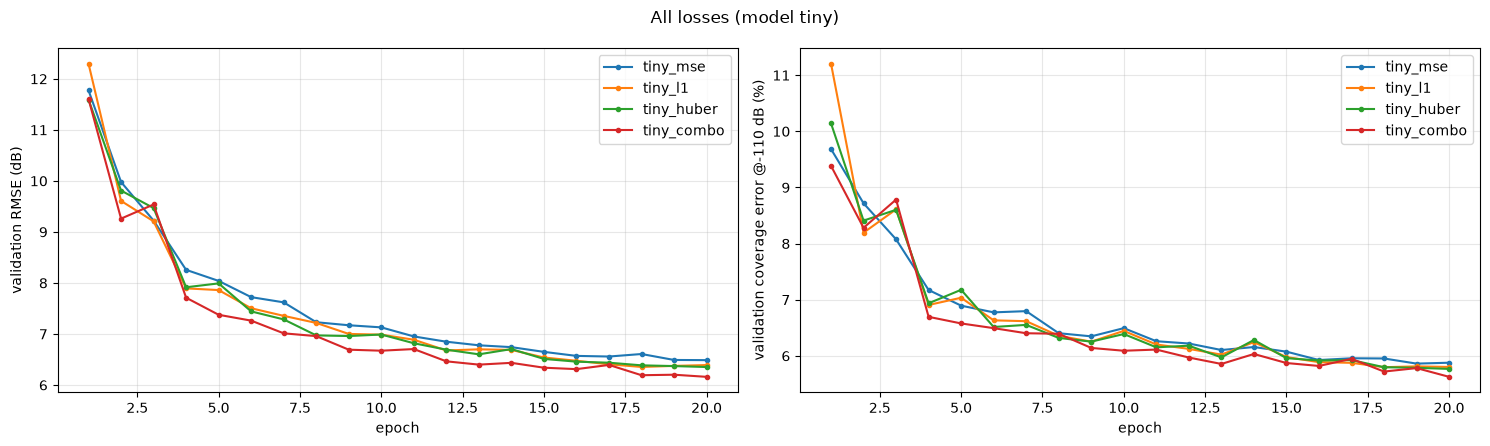

In [26]:
plot_validation_curves(loss_results, "All losses (model tiny)")

In [27]:
pd.concat({"per city family": group_table(loss_results, "family"),
           "per altitude": group_table(loss_results, "altitude")}, axis=1)

per city family                                           \
             test / blocks test / downtown test / grid ood / canyon   
tiny_mse             6.211           8.226       5.786        8.991   
tiny_l1              6.143           8.157       5.633        9.320   
tiny_huber           6.053           8.177       5.671        8.811   
tiny_combo           5.838           7.925       5.483        8.822   

                                       per altitude                          \
           ood / courtyard ood / hilly  test / 15 m test / 30 m test / 45 m   
tiny_mse             7.261       6.427        9.090       7.325       5.760   
tiny_l1              7.371       6.290        9.062       7.257       5.637   
tiny_huber           7.016       6.254        9.058       7.271       5.621   
tiny_combo           6.914       6.085        8.846       6.971       5.416   

                                                                    
           test / 60 m ood / 15 m ood / 30 m ood / 45 m ood / 60 m  
tiny_mse         4.789     11.192      8.384      5.969      4.695  
tiny_l1          4.623     11.681      8.638      5.895      4.429  
tiny_huber       4.584     11.206      8.224      5.686      4.325  
tiny_combo       4.429     11.258      8.122      5.524      4.190

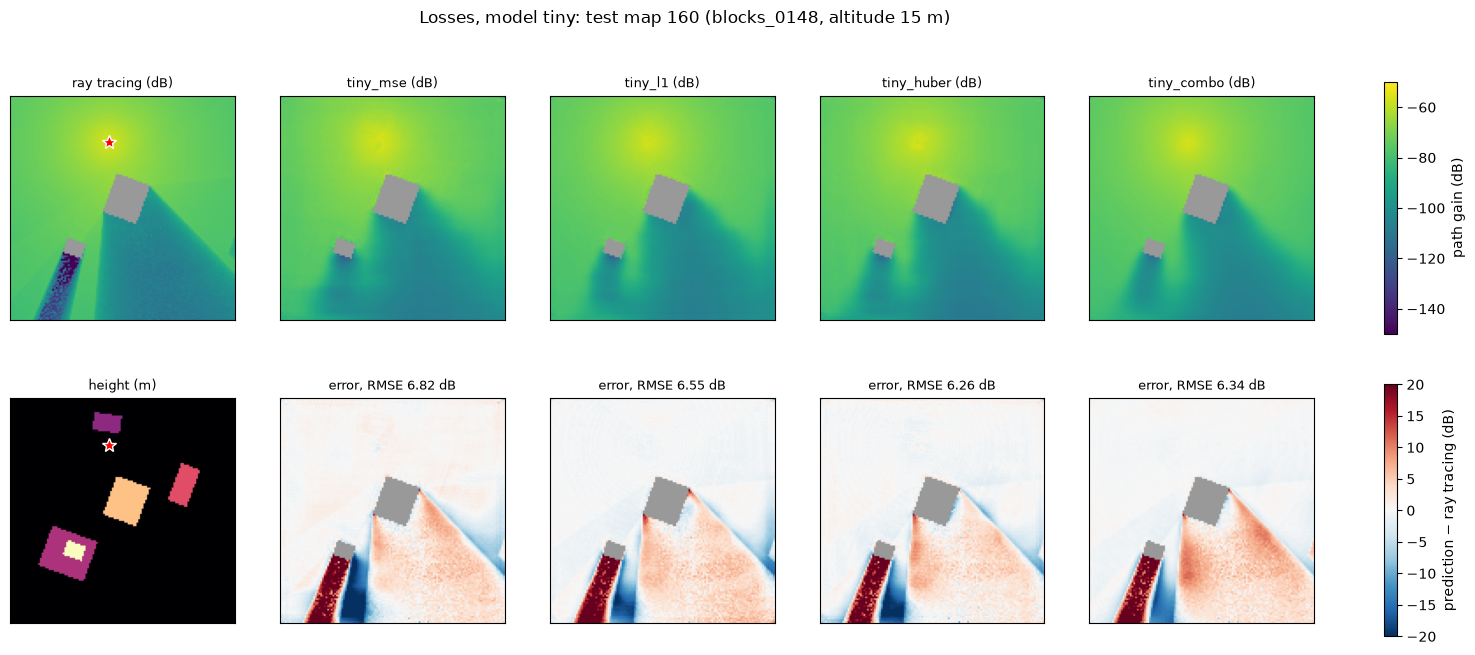

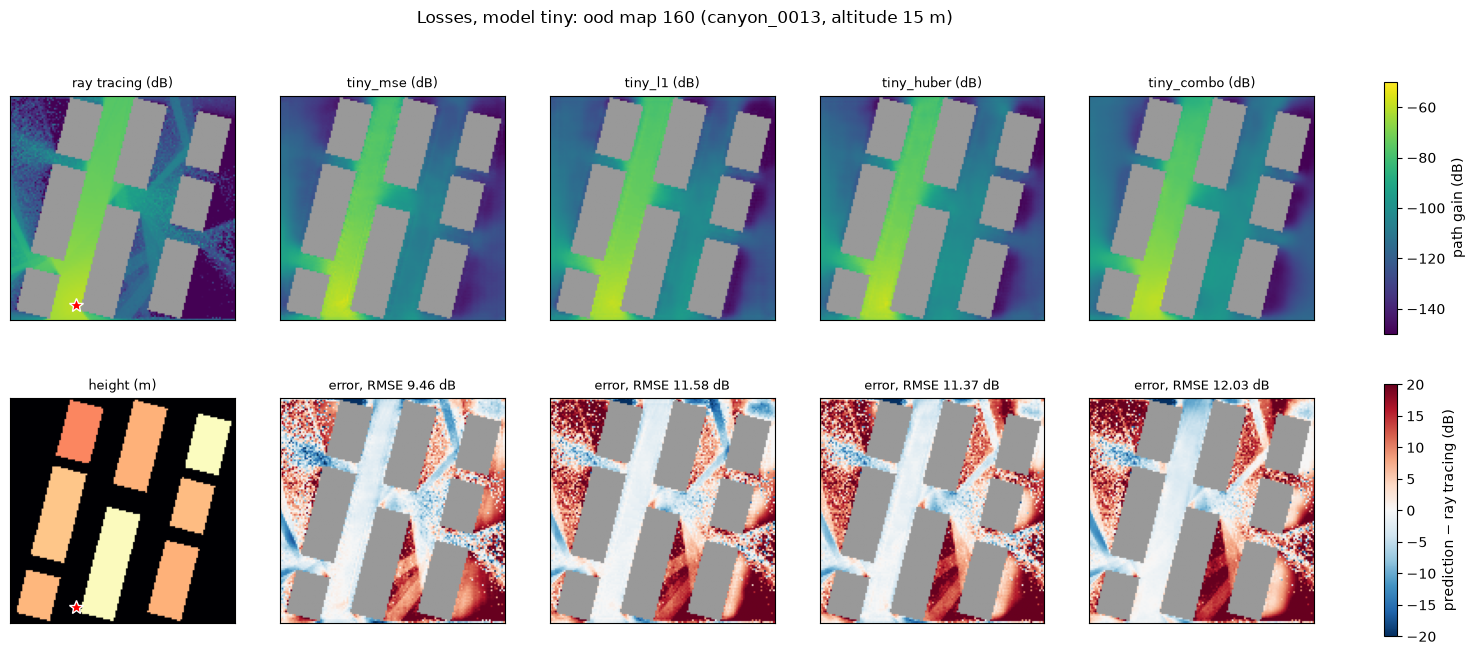

In [28]:
plot_predictions(loss_results, test_set, EXAMPLE_TEST, "Losses, model tiny")
plot_predictions(loss_results, ood_set, EXAMPLE_OOD, "Losses, model tiny")

#### Observations
* The combined loss is the most accurate on every split: RMSE 6.16, 6.42 and 7.27 dB on `val`, `test` and `ood`, about
  5 % below MSE.
* It also has the lowest MAE, boundary RMSE and coverage error on `val` and `test`, consistent with its SSIM and
  gradient terms.
* For every loss the error falls with altitude (`test`: about 9 dB at 15 m, 4.4–4.8 dB at 60 m).
* Its epochs are about 8 % slower; the prediction time is unchanged.
* The error concentrates in the low path gain areas (boundary RMSE about 10.6 dB against 6.2 dB overall); section 9
  analyses this.

### 8.5 Loss retained for studies 2 and 3
The loss with the lowest validation RMSE is retained for studies 2 and 3. The choice uses the validation split
only; `test` and `ood` play no part in it.

In [29]:
best_loss_run = min(loss_results, key=lambda r: r["summary"]["val"]["rmse_db"])
BEST_LOSS = best_loss_run["loss"]
print(f"retained loss: {BEST_LOSS} (validation RMSE {best_loss_run['summary']['val']['rmse_db']:.3f} dB)")

retained loss: combo (validation RMSE 6.160 dB)


## 9. Why the error remains high: the no-signal cells
With the combined loss the `tiny` model reaches a validation RMSE of 6.16 dB, but the error maps of section 8.4 show
that the error is not spread evenly over the map. Cells in line of sight of the station are predicted within a few
dB. The large errors are in the regions of **low path gain**: behind buildings, in narrow streets far from the
station and in the dark corners of the maps.

Part of these regions are **no-signal cells**. The ray tracer launches 10⁸ rays from the station and follows each
of them through up to 8 interactions (reflections, diffractions, diffuse scattering). When no ray crosses a cell of
the drone plane, the cell receives no power and is stored at the floor value of −150 dB. This value is therefore
not a computed path gain but a code for "below what the ray tracer resolves": the true value could be −145 dB or
−200 dB. The weakest cells that do receive a few rays are also noisy, because only a handful of random rays reach
them. In the training losses of study 1, however, −150 dB is an exact target like any other value.

The analysis below breaks down the error of the retained model by range of ray traced path gain.

In [30]:
RANGES = [("no signal (-150 dB)", None, None), ("-150 to -130 dB", -150.0, -130.0), ("-130 to -110 dB", -130.0, -110.0),
          ("-110 to -90 dB", -110.0, -90.0), ("-90 to -70 dB", -90.0, -70.0), ("-70 to -50 dB", -70.0, -40.0)]


def load_best_model(result):
    model = RMTransformer(**result["model_kwargs"]).to(DEVICE)
    ck = torch.load(STUDY_DIR / result["name"] / "best.pt", map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model"])
    return model.eval()


@torch.no_grad()
def error_by_range(predict, split, cfg=CFG):
    """Share of cells, RMSE, mean error and share of the squared error per range of ray traced path gain."""
    n, sse, se = (np.zeros(len(RANGES)) for _ in range(3))
    maps_with_no_signal = 0
    for b in range(0, len(split), cfg["eval_batch_size"]):
        h, st, alt, tgt = split.batch(np.arange(b, min(b + cfg["eval_batch_size"], len(split))), DEVICE)
        pred = predict(h, st, alt)
        tgt = tgt.clamp_min(cfg["floor_db"])
        valid = h < alt.view(-1, 1, 1) - 0.5
        silent = valid & (tgt <= cfg["floor_db"] + 1e-3)
        maps_with_no_signal += int((silent.sum((1, 2)) > 0).sum())
        err = pred - tgt
        for k, (_, lo, hi) in enumerate(RANGES):
            sel = silent if lo is None else valid & ~silent & (tgt >= lo) & (tgt < hi)
            n[k] += sel.sum().item()
            sse[k] += (err[sel] ** 2).sum().item()
            se[k] += err[sel].sum().item()
    table = pd.DataFrame({"share of valid cells (%)": 100 * n / n.sum(),
                          "RMSE (dB)": np.sqrt(sse / np.maximum(n, 1)),
                          "mean error (dB)": se / np.maximum(n, 1),
                          "share of squared error (%)": 100 * sse / sse.sum()}, index=[r[0] for r in RANGES])
    return table, 100 * maps_with_no_signal / len(split)


def range_analysis(result):
    """Metrics and error per path gain range of an experiment's best checkpoint on val, test and ood (cached)."""
    f = STUDY_DIR / result["name"] / "range_analysis.json"
    d = json.loads(f.read_text()) if f.exists() else None
    if d is None or "edge_rmse_db" not in d["summary"]["val"]:        # missing, or computed before the edge metrics
        cfg = {**CFG, **result["cfg"]}
        model = load_best_model(result)
        predict = model_predictor(model, cfg)
        d = dict(summary={}, ranges={}, maps_with_no_signal={})
        for s, ds in EVAL_SPLITS.items():
            d["summary"][s] = summarize(evaluate(predict, ds, cfg), cfg)
            table, share = error_by_range(predict, ds, cfg)
            d["ranges"][s] = table.to_dict(orient="index")
            d["maps_with_no_signal"][s] = share
        f.write_text(json.dumps(d, indent=2, default=to_json))
        del model, predict
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    d["ranges"] = {s: pd.DataFrame.from_dict(t, orient="index") for s, t in d["ranges"].items()}
    return d


retained = range_analysis(best_loss_run)
print("maps with at least one no-signal cell: " +
      ", ".join(f"{s} {retained['maps_with_no_signal'][s]:.1f} %" for s in ("test", "ood")))
pd.concat({s: retained["ranges"][s] for s in ("test", "ood")}, axis=1)

maps with at least one no-signal cell: test 57.6 %, ood 57.7 %


test                            \
                    share of valid cells (%) RMSE (dB) mean error (dB)   
no signal (-150 dB)                    2.028    19.574          14.780   
-150 to -130 dB                        1.788    17.895          12.630   
-130 to -110 dB                        9.232     9.979           2.882   
-110 to -90 dB                        27.375     7.234           0.898   
-90 to -70 dB                         54.641     4.819          -1.390   
-70 to -50 dB                          4.936     1.798          -0.609   

                                                                    ood  \
                    share of squared error (%) share of valid cells (%)   
no signal (-150 dB)                     15.582                    3.825   
-150 to -130 dB                         11.485                    2.127   
-130 to -110 dB                         18.438                   10.971   
-110 to -90 dB                          28.728                   24.192   
-90 to -70 dB                           25.448                   53.439   
-70 to -50 dB                            0.320                    5.446   

                                                                          
                    RMSE (dB) mean error (dB) share of squared error (%)  
no signal (-150 dB)    28.233          23.970                     43.121  
-150 to -130 dB        21.545          18.070                     13.964  
-130 to -110 dB         9.847           5.490                     15.045  
-110 to -90 dB          6.474           1.139                     14.337  
-90 to -70 dB           4.214          -1.336                     13.419  
-70 to -50 dB           1.219          -0.464                      0.114

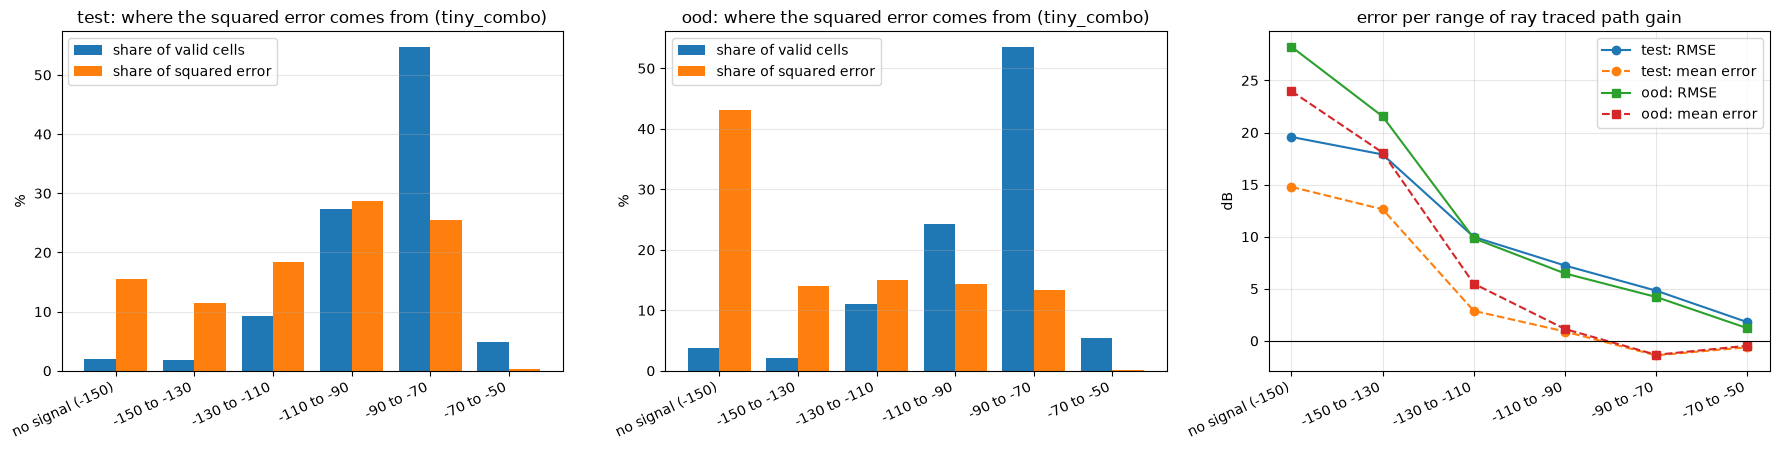

,15 m,30 m,45 m,60 m
no-signal cells (% of valid cells),,,,
val,4.968,1.681,0.696,0.274
test,5.727,2.040,0.689,0.232
ood,10.183,4.477,1.313,0.369


In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
labels = [r[0].replace(" dB", "") for r in RANGES]
x = np.arange(len(RANGES))
for ax, s in zip(axes[:2], ("test", "ood")):
    t = retained["ranges"][s]
    ax.bar(x - 0.2, t["share of valid cells (%)"], 0.4, label="share of valid cells")
    ax.bar(x + 0.2, t["share of squared error (%)"], 0.4, label="share of squared error")
    ax.set_xticks(x, labels, rotation=25, ha="right")
    ax.set_ylabel("%")
    ax.set_title(f"{s}: where the squared error comes from ({best_loss_run['name']})")
    ax.legend()
    ax.grid(alpha=0.3, axis="y")
for s, marker in (("test", "o"), ("ood", "s")):
    axes[2].plot(x, retained["ranges"][s]["RMSE (dB)"], marker=marker, label=f"{s}: RMSE")
    axes[2].plot(x, retained["ranges"][s]["mean error (dB)"], marker=marker, ls="--", label=f"{s}: mean error")
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_xticks(x, labels, rotation=25, ha="right")
axes[2].set_ylabel("dB")
axes[2].set_title("error per range of ray traced path gain")
axes[2].legend()
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()


def no_signal_share(split):
    """Share of valid cells without signal, per altitude (%)."""
    out = {}
    for a in np.unique(split.altitude.numpy()):
        k = np.where(split.altitude.numpy() == a)[0]
        h = split.heights[split.scene_idx[torch.as_tensor(k)]]
        valid = h < float(a) - 0.5
        out[f"{a:g} m"] = 100 * float((valid & (split.target[torch.as_tensor(k)] <= CFG["floor_db"] + 1e-3)).sum()
                                      / valid.sum())
    return out


pd.DataFrame({s: no_signal_share(d) for s, d in EVAL_SPLITS.items()}).T.rename_axis("no-signal cells (% of valid cells)")

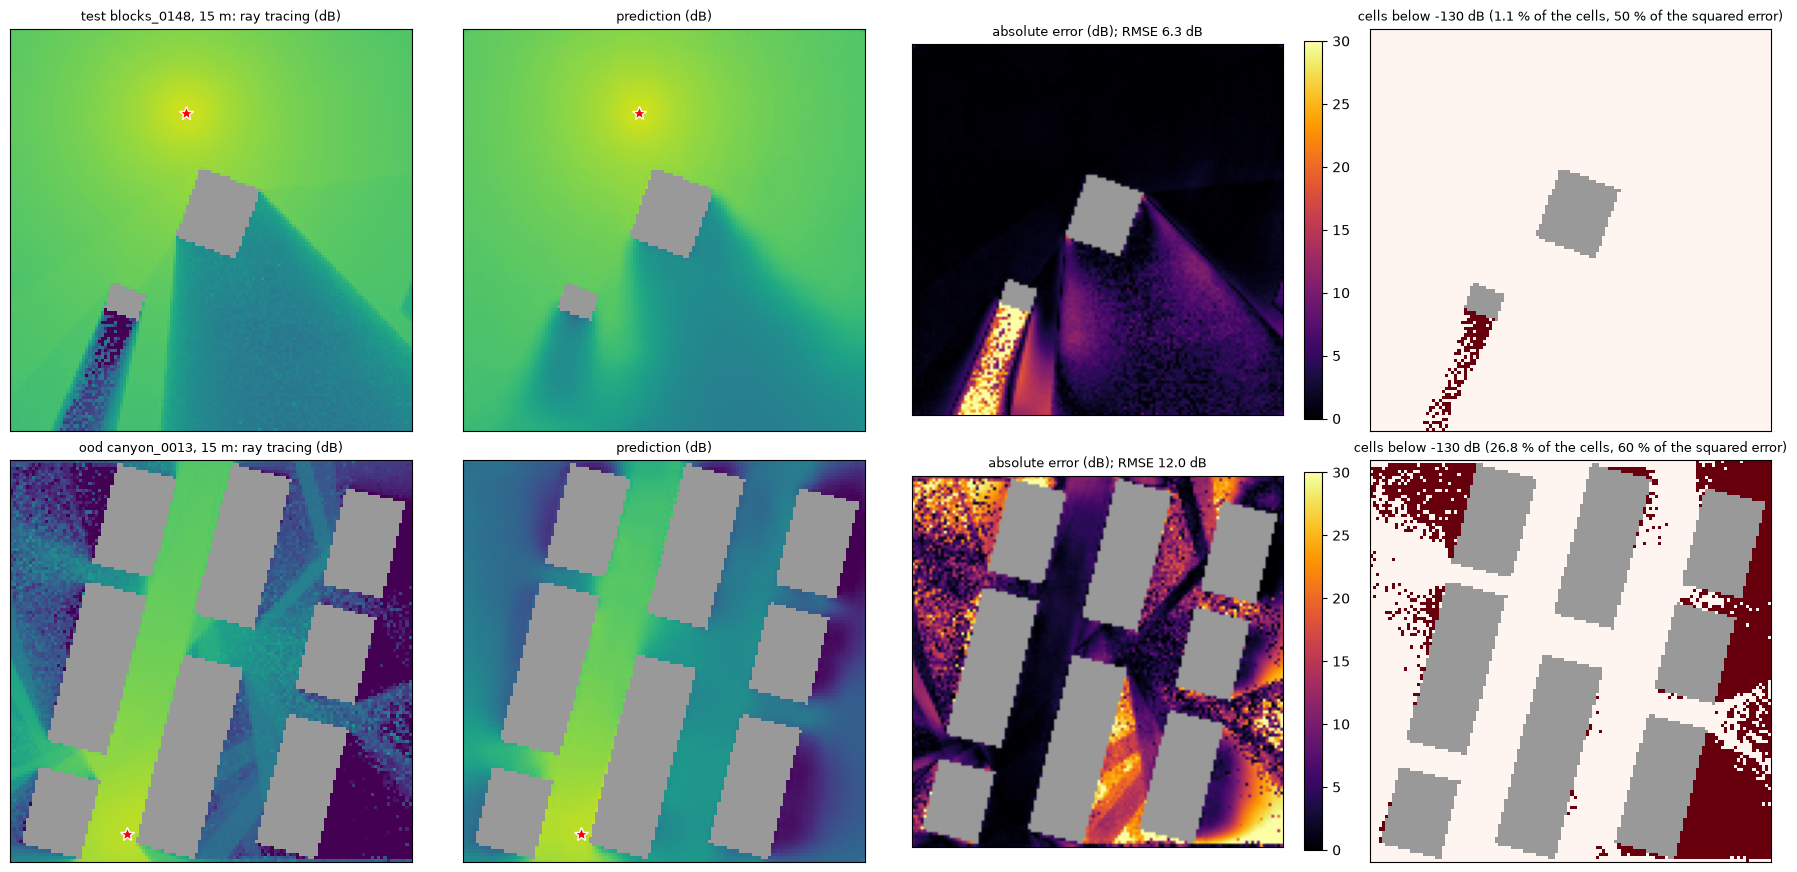

In [32]:
@torch.no_grad()
def plot_low_gain_errors(result, examples, threshold_db=-130.0):
    """Ray traced map, prediction, absolute error and the cells below threshold_db, for (split, map index) pairs."""
    model = load_best_model(result)
    predict = model_predictor(model, {**CFG, **result["cfg"]})
    fig, axes = plt.subplots(len(examples), 4, figsize=(18, 4.4 * len(examples)), squeeze=False)
    for row, (split, k) in zip(axes, examples):
        h, st, alt, tgt = split.batch([k], DEVICE)
        valid = (h < alt.view(-1, 1, 1) - 0.5)[0].cpu().numpy()
        target = tgt.clamp_min(CFG["floor_db"])[0].cpu().numpy()
        pred = predict(h, st, alt)[0].cpu().numpy()
        low = valid & (target < threshold_db)
        err = np.abs(pred - target)
        name = split.scene_names[int(split.scene_idx[k])]
        show_map(row[0], target, valid, f"{split.name} {name}, {float(alt[0]):.0f} m: ray tracing (dB)",
                 CFG["floor_db"], CFG["max_db"], station=st[0].cpu())
        show_map(row[1], pred, valid, "prediction (dB)", CFG["floor_db"], CFG["max_db"], station=st[0].cpu())
        im = show_map(row[2], err, valid, f"absolute error (dB); RMSE {np.sqrt(np.mean(err[valid] ** 2)):.1f} dB",
                      0, 30, cmap="inferno")
        plt.colorbar(im, ax=row[2], fraction=0.046)
        show_map(row[3], low.astype(float), valid, f"cells below {threshold_db:g} dB ({100 * low[valid].mean():.1f} % "
                 f"of the cells, {100 * (err[low] ** 2).sum() / (err[valid] ** 2).sum():.0f} % of the squared error)",
                 0, 1, cmap="Reds")
    plt.tight_layout()
    plt.show()
    del model


plot_low_gain_errors(best_loss_run, [(test_set, EXAMPLE_TEST), (ood_set, EXAMPLE_OOD)])

#### What the analysis shows
* **The error grows as the path gain decreases.** For the retained model the RMSE is below 2 dB above −70 dB,
  about 5 dB between −90 and −70 dB, about 10 dB between −130 and −110 dB and close to 20 dB on `test` (close to
  30 dB on `ood`) in the no-signal cells.
* **A few cells carry a large part of the error.** The cells below −130 dB are about 4 % of the valid cells of
  `test` but cause about a quarter of its squared error; on `ood` they are about 6 % of the cells and cause more than
  half of it. The no-signal cells alone account for about 16 % (`test`) and 43 % (`ood`) of the squared error. They
  are the main reason why the `ood` RMSE is higher than the `test` RMSE, whereas the error on cells with signal is
  similar on both splits.
* **The model overestimates weak signals.** The mean error is strongly positive below −130 dB (about +15 dB on the
  no-signal cells of `test`, +24 dB on `ood`): where the ray tracer finds no signal, the model predicts a weak but
  existing one. For mission planning this is the dangerous direction, since it can predict a link where there is
  none.
* **The problem is common.** More than half of the maps contain at least one no-signal cell, and these cells are most
  frequent at low altitude, where buildings block the most paths.

For a drone link these differences hardly matter: with a 20 dBm transmitter and a receiver sensitivity of −100 dBm a
path gain of at least −120 dB is needed, so every value below about −130 dB means "no link", whether it is −135 dB
or −150 dB. Training the model to reproduce the exact −150 dB code makes it spend capacity on values that carry no
information for the application, and penalises predictions such as −140 dB that are physically reasonable. The
next study therefore compares training strategies that treat the no-signal cells for what they are, or that change
the weight of the weak-signal cells in the loss.

## 10. Study 2: treatment of the no-signal cells
Model `tiny`, retained loss, same protocol as study 1. Five treatments are compared with the baseline of study 1,
in which no-signal cells are ordinary targets at −150 dB. The first three change what the model is asked to predict
in the no-signal cells, using the threshold τ = −130 dB below which no link is possible (section 9). The last two keep
the targets unchanged and change how much the errors of weak-signal cells count in the loss. The code is in
section 5.1.

| treatment | training target of a no-signal cell | cells between −150 and −130 dB | weight of an error | prediction |
|---|---|---|---|---|
| baseline (`none`) | −150 dB, exact | exact value | 1 | network output |
| **truncation** (`truncate`) | τ = −130 dB | raised to τ | 1 | clipped to ≥ τ |
| **censored target** (`censor`) | any value ≤ τ | exact value | 1 | network output |
| **two outputs** (`two_output`) | no path gain target; "no signal" for the classifier | exact value | 1 | −150 dB where P(signal) < 0.5, else the predicted path gain |
| **asymmetric penalty** (`asymmetric`) | −150 dB, exact | exact value | 4 for an overestimation of a cell below −110 dB, else 1 | network output |
| **re-weighting** (`reweight`) | −150 dB, exact | exact value | inverse of the (smoothed) frequency of the cell's path gain | network output |

* **Truncation.** Every target below τ is replaced by τ, as RadioUNet truncates its maps near the noise floor. The
  jump between −150 dB and the weakest received values disappears, and the model no longer has to distinguish
  values that are all "no link". The values between −150 and −130 dB are lost as well.
* **Censored target.** A no-signal cell only tells that the path gain is *below* the floor. It is treated as an
  inequality, as in censored (Tobit) regression: there is no penalty when the prediction is below τ, and the
  penalty grows with the excess above τ. In practice the target of a no-signal cell is replaced by
  min(prediction, τ), with the prediction held constant: the error is zero for a prediction ≤ τ and equal to
  prediction − τ otherwise. This works with any loss, including the SSIM and gradient terms, and leaves the cells
  that received a signal unchanged.
* **Two outputs.** The output head produces two maps: the path gain and the logit of the probability that the cell
  receives a signal. The path gain map is trained with the retained loss on the cells with signal only, the
  probability with binary cross-entropy on all valid cells (weight 0.1). At prediction time a cell with
  P(signal) < 0.5 is set to −150 dB. This separates the two questions "is there a signal?" and "how strong is it?",
  as suggested in the dataset card.
* **Asymmetric penalty.** Section 9 showed that the model overestimates weak signals (mean error +15 dB on the
  no-signal cells of `test`, +24 dB on `ood`), which is the dangerous error for a drone mission: a link is predicted
  where there is none. In cells weaker than −110 dB (the coverage threshold), an error in which the prediction is
  above the ray tracing counts 4 times; an underestimation and every error in stronger cells count once. Asymmetric
  losses of this kind are used in radio environment prediction to make one direction of error costlier (ProSpire).
* **Re-weighting.** Weak and no-signal cells are rare in the training data, and errors on rare target values tend to
  be large (imbalanced regression). The share of training cells in every 5 dB bin of path gain is measured on
  2,000 training maps and smoothed with a Gaussian kernel of one bin (label distribution smoothing, Yang et al.,
  2021). The weight of a bin is the inverse square root of its smoothed share, normalised so that the average
  weight over the cells is 1 and capped at 10. Rare bins count more: the weak-signal and no-signal bins (weights of
  about 2 to 3.5) and, because the strongest values are rare too, the few cells right next to the station. The
  weights are shown below.

**Evaluation.** The standard RMSE compares every prediction with −150 dB on the no-signal cells, so it penalises
truncation and censoring by construction (a prediction of −135 dB on a no-signal cell counts as a 15 dB error). The
treatments are therefore compared on the **link RMSE** `rmse_link_db`, where prediction and ray tracing are both
clipped at τ = −130 dB before computing the error: values that are all too weak for a link count as equal, all
others as usual. The standard RMSE, the RMSE on cells with signal, the coverage prediction error, the share of
no-signal cells where a link is predicted (`no_signal_false_link`, at ≥ −110 dB) and the share of no-signal cells
recognised as such (`no_signal_detected`, at ≤ −130 dB) are reported as well. Within each run of this study the
checkpoint with the lowest validation link RMSE is kept.

In [33]:
tiny_truncate = run_experiment(experiment_name("tiny", BEST_LOSS, "truncate"), "tiny", BEST_LOSS, "truncate")

tiny_combo_truncate: finished earlier, results loaded from runs\loss_and_size_study\tiny_combo_truncate\results.json


In [34]:
tiny_censor = run_experiment(experiment_name("tiny", BEST_LOSS, "censor"), "tiny", BEST_LOSS, "censor")

tiny_combo_censor: finished earlier, results loaded from runs\loss_and_size_study\tiny_combo_censor\results.json


In [35]:
tiny_two_output = run_experiment(experiment_name("tiny", BEST_LOSS, "two_output"), "tiny", BEST_LOSS, "two_output")

tiny_combo_two_output: finished earlier, results loaded from runs\loss_and_size_study\tiny_combo_two_output\results.json


In [36]:
tiny_asymmetric = run_experiment(experiment_name("tiny", BEST_LOSS, "asymmetric"), "tiny", BEST_LOSS, "asymmetric")

tiny_combo_asymmetric: finished earlier, results loaded from runs\loss_and_size_study\tiny_combo_asymmetric\results.json


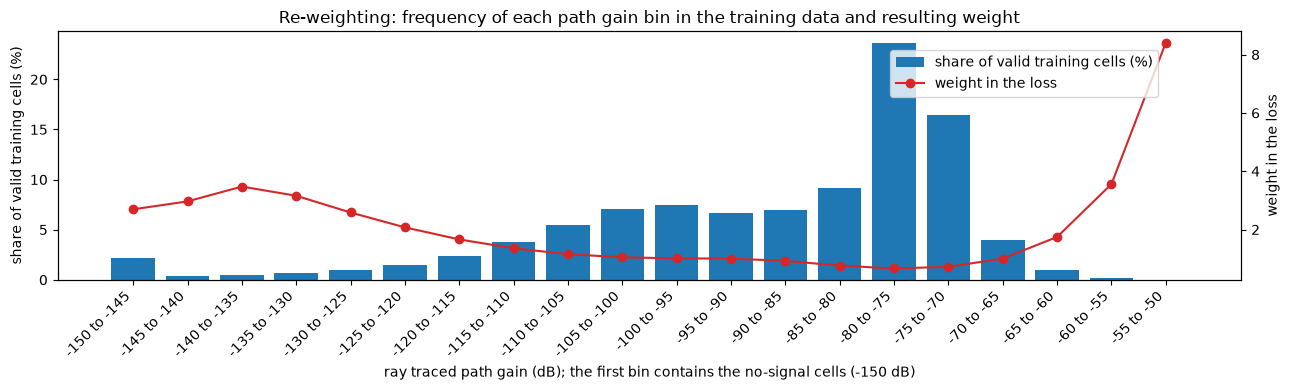

bin (dB),-150 to -145,-145 to -140,-140 to -135,-135 to -130,-130 to -125,-125 to -120,-120 to -115,-115 to -110,-110 to -105,-105 to -100,-100 to -95,-95 to -90,-90 to -85,-85 to -80,-80 to -75,-75 to -70,-70 to -65,-65 to -60,-60 to -55,-55 to -50
share of valid cells (%),2.206,0.330,0.453,0.640,0.968,1.491,2.361,3.761,5.497,7.037,7.442,6.639,6.944,9.133,23.611,16.48,3.942,0.925,0.137,0.002
weight,2.693,2.965,3.473,3.158,2.584,2.074,1.661,1.355,1.154,1.046,1.011,1.002,0.925,0.762,0.664,0.72,1.004,1.745,3.561,8.411


In [37]:
# weights of the "reweight" treatment, computed from the training split
REWEIGHT = reweight_table(train_set)
fig, ax = plt.subplots(figsize=(13, 4))
x = np.arange(len(REWEIGHT))
ax.bar(x, REWEIGHT["share of valid cells (%)"], color="tab:blue", label="share of valid training cells (%)")
ax.set_ylabel("share of valid training cells (%)")
ax.set_xticks(x, REWEIGHT["bin (dB)"], rotation=45, ha="right")
ax2 = ax.twinx()
ax2.plot(x, REWEIGHT["weight"], "o-", color="tab:red", label="weight in the loss")
ax2.set_ylabel("weight in the loss")
ax.set_xlabel("ray traced path gain (dB); the first bin contains the no-signal cells (-150 dB)")
ax.set_title("Re-weighting: frequency of each path gain bin in the training data and resulting weight")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.tight_layout()
plt.show()
REWEIGHT.set_index("bin (dB)").T

In [38]:
tiny_reweight = run_experiment(experiment_name("tiny", BEST_LOSS, "reweight"), "tiny", BEST_LOSS, "reweight",
                               reweight_table=REWEIGHT["weight"].tolist())

tiny_combo_reweight: finished earlier, results loaded from runs\loss_and_size_study\tiny_combo_reweight\results.json


### 10.1 Comparison of the treatments
All values in dB unless stated otherwise; the baseline is the retained run of study 1.

In [39]:
floor_results = [best_loss_run, tiny_truncate, tiny_censor, tiny_two_output, tiny_asymmetric, tiny_reweight]
floor_analysis = {r["name"]: range_analysis(r) for r in floor_results}


def floor_table(results):
    rows = []
    for r in results:
        s = floor_analysis[r["name"]]["summary"]
        rows.append(pd.Series({
            "no-signal cells": r.get("floor_method", "none"),
            "val link RMSE": s["val"]["rmse_link_db"], "test link RMSE": s["test"]["rmse_link_db"],
            "ood link RMSE": s["ood"]["rmse_link_db"],
            "val RMSE": s["val"]["rmse_db"], "test RMSE": s["test"]["rmse_db"], "ood RMSE": s["ood"]["rmse_db"],
            "test RMSE signal": s["test"]["rmse_signal_db"], "ood RMSE signal": s["ood"]["rmse_signal_db"],
            f"test cov. error @{T_REF:g} (%)": 100 * s["test"][f"cov_err@{T_REF:g}"],
            f"ood cov. error @{T_REF:g} (%)": 100 * s["ood"][f"cov_err@{T_REF:g}"],
            "test no-signal: link predicted (%)": 100 * s["test"]["no_signal_false_link"],
            "ood no-signal: link predicted (%)": 100 * s["ood"]["no_signal_false_link"],
            "test no-signal: detected (%)": 100 * s["test"]["no_signal_detected"],
            "ood no-signal: detected (%)": 100 * s["ood"]["no_signal_detected"]}, name=r["name"]))
    return pd.DataFrame(rows)


floor_table(floor_results)

,no-signal cells,val link RMSE,test link RMSE,ood link RMSE,val RMSE,test RMSE,ood RMSE,test RMSE signal,ood RMSE signal,test cov. error @-110 (%),ood cov. error @-110 (%),test no-signal: link predicted (%),ood no-signal: link predicted (%),test no-signal: detected (%),ood no-signal: detected (%)
tiny_combo,none,5.499,5.667,5.812,6.160,6.416,7.273,6.555,6.467,6.168,7.857,3.163,15.873,65.419,39.633
tiny_combo_truncate,truncate,5.484,5.661,5.775,6.291,6.562,7.453,6.397,6.382,6.225,7.762,2.818,15.389,8.848,3.881
tiny_combo_censor,censor,5.495,5.662,5.868,6.248,6.495,7.488,6.380,6.463,6.209,7.994,3.599,15.921,45.418,24.149
tiny_combo_two_output,two_output,5.492,5.626,5.802,6.274,6.512,7.408,6.526,6.449,6.211,7.854,3.770,15.457,45.513,23.816
tiny_combo_asymmetric,asymmetric,6.055,6.365,6.075,6.714,7.144,7.294,7.799,6.987,6.935,7.730,1.008,12.018,85.152,59.202
tiny_combo_reweight,reweight,5.655,5.912,5.952,6.260,6.603,7.317,6.919,6.648,6.291,7.870,1.900,14.530,73.500,45.424


In [40]:
# RMSE (dB) per range of ray traced path gain
pd.concat({s: pd.DataFrame({r["name"]: floor_analysis[r["name"]]["ranges"][s]["RMSE (dB)"] for r in floor_results}).T
           for s in ("test", "ood")}, axis=1)

test                                  \
                      no signal (-150 dB) -150 to -130 dB -130 to -110 dB   
tiny_combo                         19.574          17.895           9.979   
tiny_combo_truncate                24.978          18.262           8.587   
tiny_combo_censor                  23.765          18.447           9.057   
tiny_combo_two_output              22.375          19.275           9.538   
tiny_combo_asymmetric              13.026          13.424          12.165   
tiny_combo_reweight                16.962          15.766          10.345   

                                                                  \
                      -110 to -90 dB -90 to -70 dB -70 to -50 dB   
tiny_combo                     7.234         4.819         1.798   
tiny_combo_truncate            7.171         4.896         1.736   
tiny_combo_censor              7.145         4.706         1.721   
tiny_combo_two_output          7.091         4.832         1.788   
tiny_combo_asymmetric          9.611         5.612         2.101   
tiny_combo_reweight            8.010         5.205         2.028   

                                      ood                                  \
                      no signal (-150 dB) -150 to -130 dB -130 to -110 dB   
tiny_combo                         28.233          21.545           9.847   
tiny_combo_truncate                30.517          21.430           9.346   
tiny_combo_censor                  30.314          21.969           9.841   
tiny_combo_two_output              29.817          22.169           9.642   
tiny_combo_asymmetric              23.700          17.488          10.139   
tiny_combo_reweight                26.970          20.280           9.992   

                                                                  
                      -110 to -90 dB -90 to -70 dB -70 to -50 dB  
tiny_combo                     6.474         4.214         1.219  
tiny_combo_truncate            6.463         4.247         1.165  
tiny_combo_censor              6.500         4.102         1.166  
tiny_combo_two_output          6.372         4.204         1.201  
tiny_combo_asymmetric          8.272         4.837         1.466  
tiny_combo_reweight            7.040         4.476         1.378

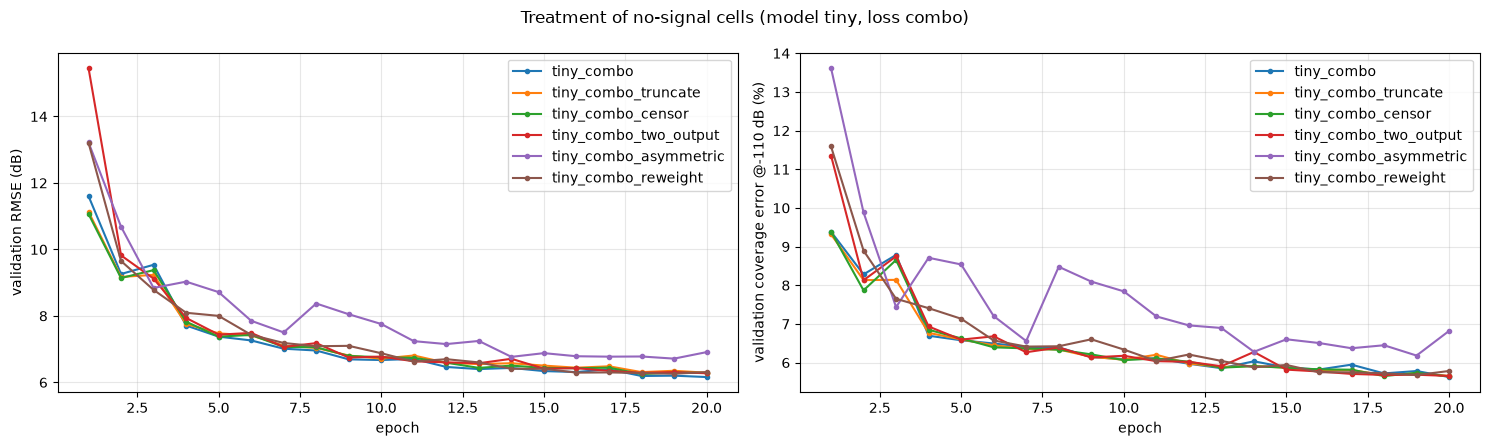

In [41]:
plot_validation_curves(floor_results, f"Treatment of no-signal cells (model tiny, loss {BEST_LOSS})")

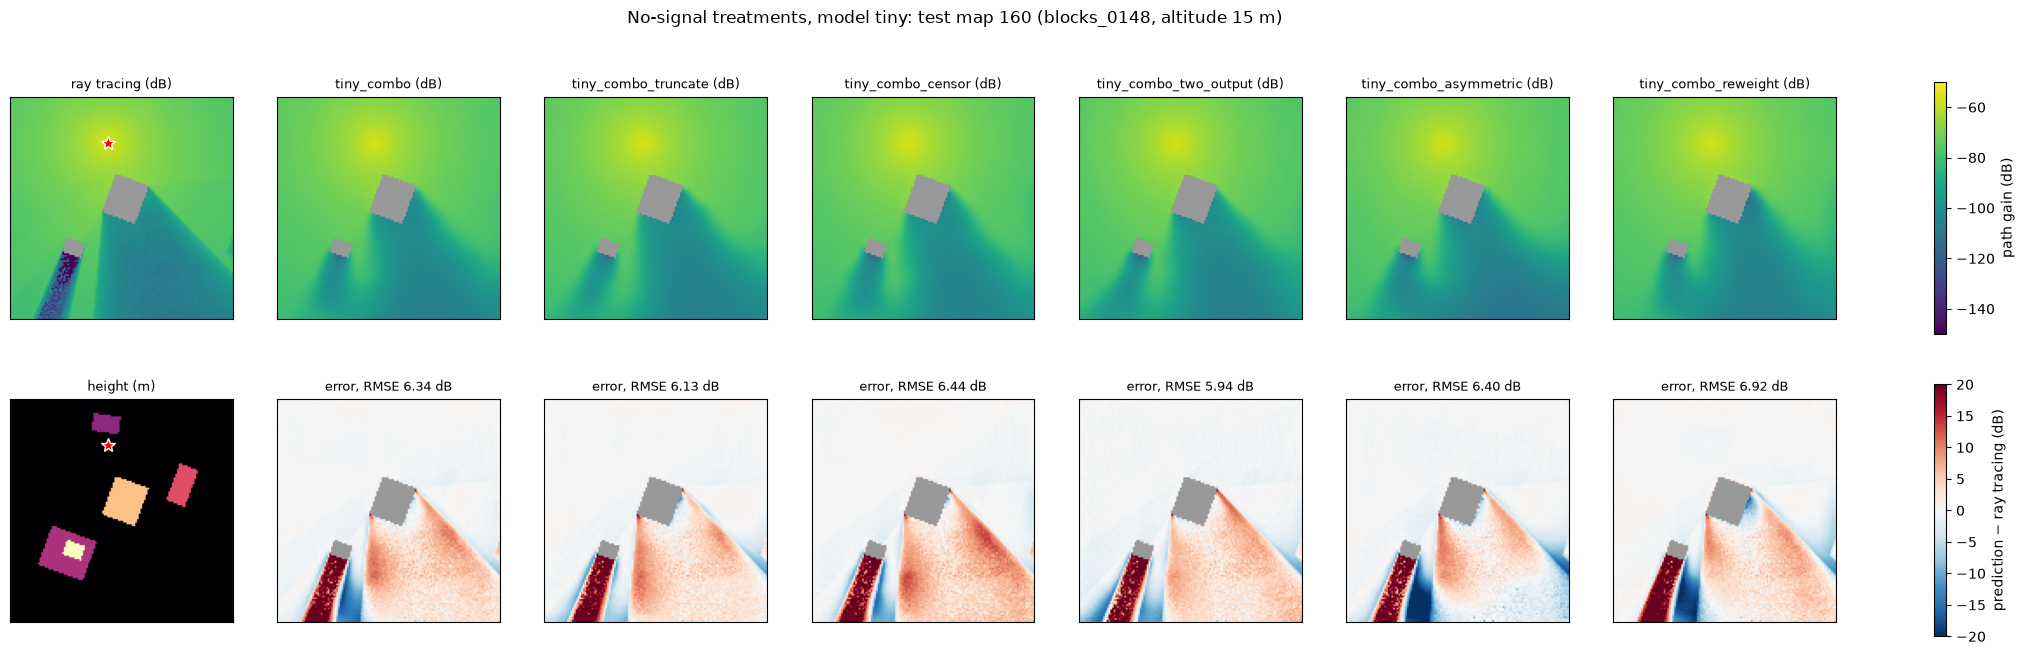

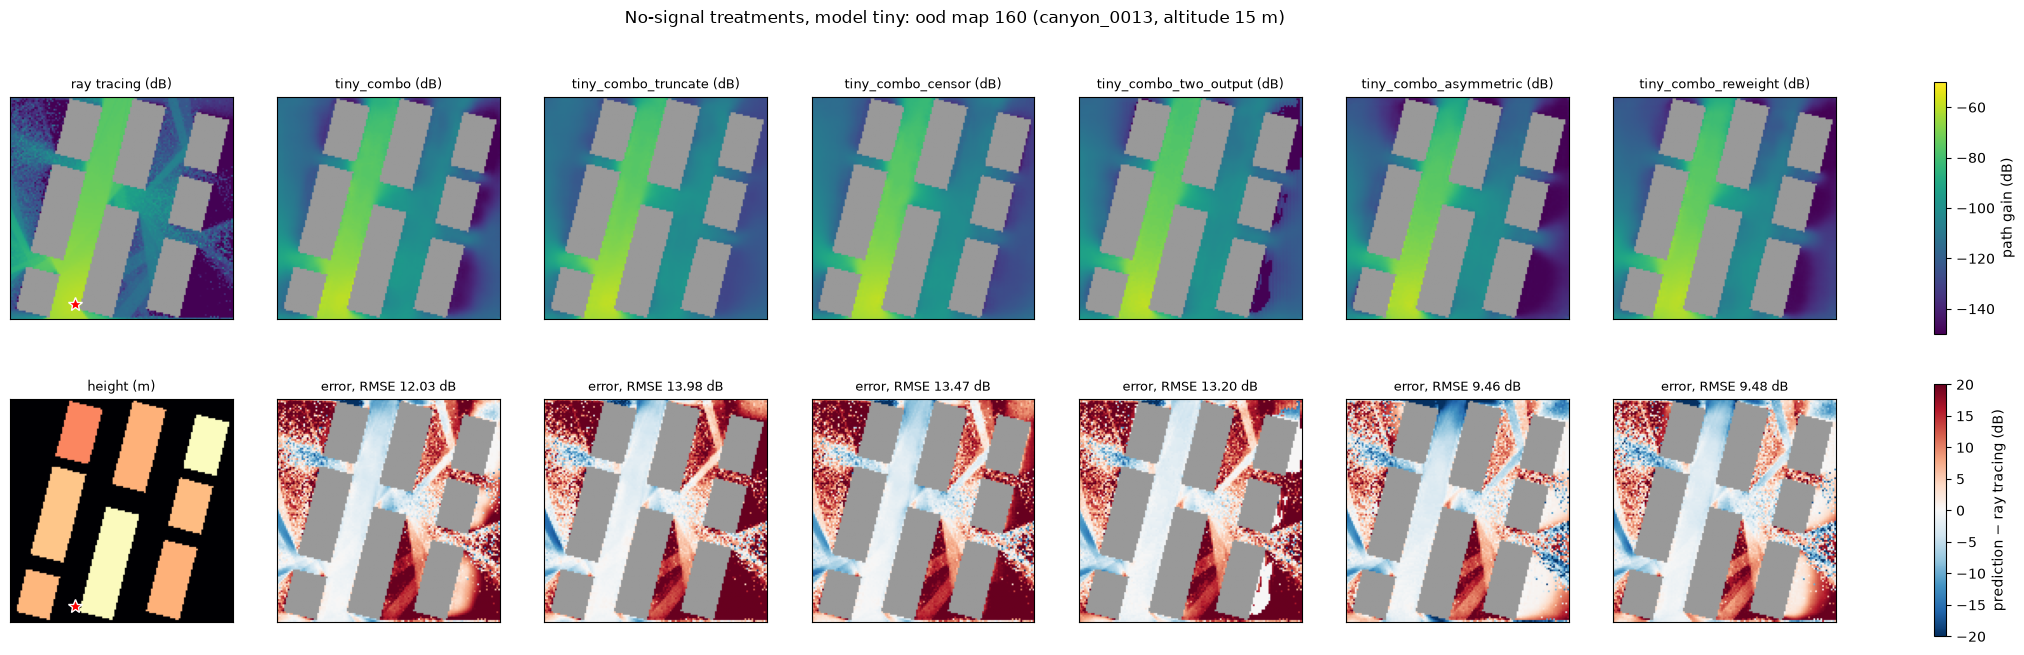

In [42]:
plot_predictions(floor_results, test_set, EXAMPLE_TEST, "No-signal treatments, model tiny")
plot_predictions(floor_results, ood_set, EXAMPLE_OOD, "No-signal treatments, model tiny")

#### Observations
* **Truncation, censored target and two outputs are tied with the baseline** on the link RMSE (5.48–5.50 dB on `val`,
  differences ≤ 0.04 dB). They improve the cells with signal (test 6.38–6.53 dB against 6.56 dB) but worsen the
  no-signal cells (22.4–25.0 dB against 19.6 dB), and do not reduce false links (test 2.8–3.8 % against 3.2 %).
* **Asymmetric penalty and re-weighting reduce false links** (test 1.0 % and 1.9 % against 3.2 %, ood 12.0 % and
  14.5 % against 15.9 %) and recognise more no-signal cells (test 85 % and 74 % against 65 %).
* **They cost accuracy on the common cells:** validation link RMSE 6.06 and 5.66 dB against 5.50 dB; test RMSE between
  −110 and −90 dB 9.6 and 8.0 dB against 7.2 dB.
* **No treatment improves both accuracy and safety:** the choice depends on which goal matters more. In `ood`,
  12–16 % of the no-signal cells still receive a predicted link.
* One run per treatment: differences of a few hundredths of a dB are not significant.

## 11. Where the error lies: the edges of the coverage map
Study 2 did not reduce the overall error much. Its maps (section 10.1) show that the remaining errors form thin
lines along the borders of the shadows, where the path gain changes abruptly. In image-to-image prediction such
transitions are a known weak point: a network trained with pixel losses tends to blur them, because a smooth
transition is a compromise that is half right on both sides.

The analysis below measures how the error of the retained model (study 1, no treatment of the no-signal cells)
depends on the distance to the nearest edge of the ray traced map (section 5.2). Prediction and ray tracing are
clipped at −130 dB, so the no-signal cells of section 9 play no part in it.

In [43]:
EDGE_BANDS = ["edge cell", "1-2 cells from an edge", "3-5 cells from an edge", "more than 5 cells"]


@torch.no_grad()
def error_near_edges(predict, split, cfg=CFG):
    """Share of cells, RMSE and share of the squared error by distance to the nearest edge, and near buildings."""
    link = cfg["floor_threshold_db"]
    n, sse = np.zeros(6), np.zeros(6)
    for b in range(0, len(split), cfg["eval_batch_size"]):
        h, st, alt, tgt = split.batch(np.arange(b, min(b + cfg["eval_batch_size"], len(split))), DEVICE)
        pred = predict(h, st, alt).clamp_min(link)
        t = tgt.clamp_min(link)
        valid = h < alt.view(-1, 1, 1) - 0.5
        on_edge = near_edges(t, valid, {**cfg, "edge_width": 0})
        within2, within5 = near_edges(t, valid, {**cfg, "edge_width": 2}), near_edges(t, valid, {**cfg, "edge_width": 5})
        building = valid & (F.max_pool2d((~valid).float()[:, None], 5, 1, 2)[:, 0] > 0)
        groups = [on_edge, within2 & ~on_edge, within5 & ~within2, valid & ~within5, building, valid & ~building]
        err2 = (pred - t) ** 2
        for k, m in enumerate(groups):
            n[k] += m.sum().item()
            sse[k] += err2[m].sum().item()
    rows = EDGE_BANDS + ["within 2 cells of a building", "farther from buildings"]
    table = pd.DataFrame({"share of valid cells (%)": 100 * n / n[:4].sum(),
                          "RMSE (dB)": np.sqrt(sse / np.maximum(n, 1)),
                          "share of squared error (%)": 100 * sse / sse[:4].sum()}, index=rows)
    return table


retained_model = load_best_model(best_loss_run)
retained_predict = model_predictor(retained_model, {**CFG, **best_loss_run["cfg"]})
edge_tables = {s: error_near_edges(retained_predict, d) for s, d in (("test", test_set), ("ood", ood_set))}
pd.concat(edge_tables, axis=1)

test            \
                             share of valid cells (%) RMSE (dB)   
edge cell                                      10.537     9.518   
1-2 cells from an edge                         23.135     8.233   
3-5 cells from an edge                         16.964     6.273   
more than 5 cells                              49.364     3.264   
within 2 cells of a building                    3.556     8.199   
farther from buildings                         96.444     6.004   

                                                         \
                             share of squared error (%)   
edge cell                                        25.687   
1-2 cells from an edge                           42.199   
3-5 cells from an edge                           17.962   
more than 5 cells                                14.151   
within 2 cells of a building                      6.434   
farther from buildings                           93.566   

                                                  ood            \
                             share of valid cells (%) RMSE (dB)   
edge cell                                       9.512     9.893   
1-2 cells from an edge                         20.314     8.774   
3-5 cells from an edge                         15.065     6.673   
more than 5 cells                              55.108     4.033   
within 2 cells of a building                    3.191     9.704   
farther from buildings                         96.809     6.233   

                                                         
                             share of squared error (%)  
edge cell                                        22.921  
1-2 cells from an edge                           38.502  
3-5 cells from an edge                           16.515  
more than 5 cells                                22.062  
within 2 cells of a building                      7.397  
farther from buildings                           92.603

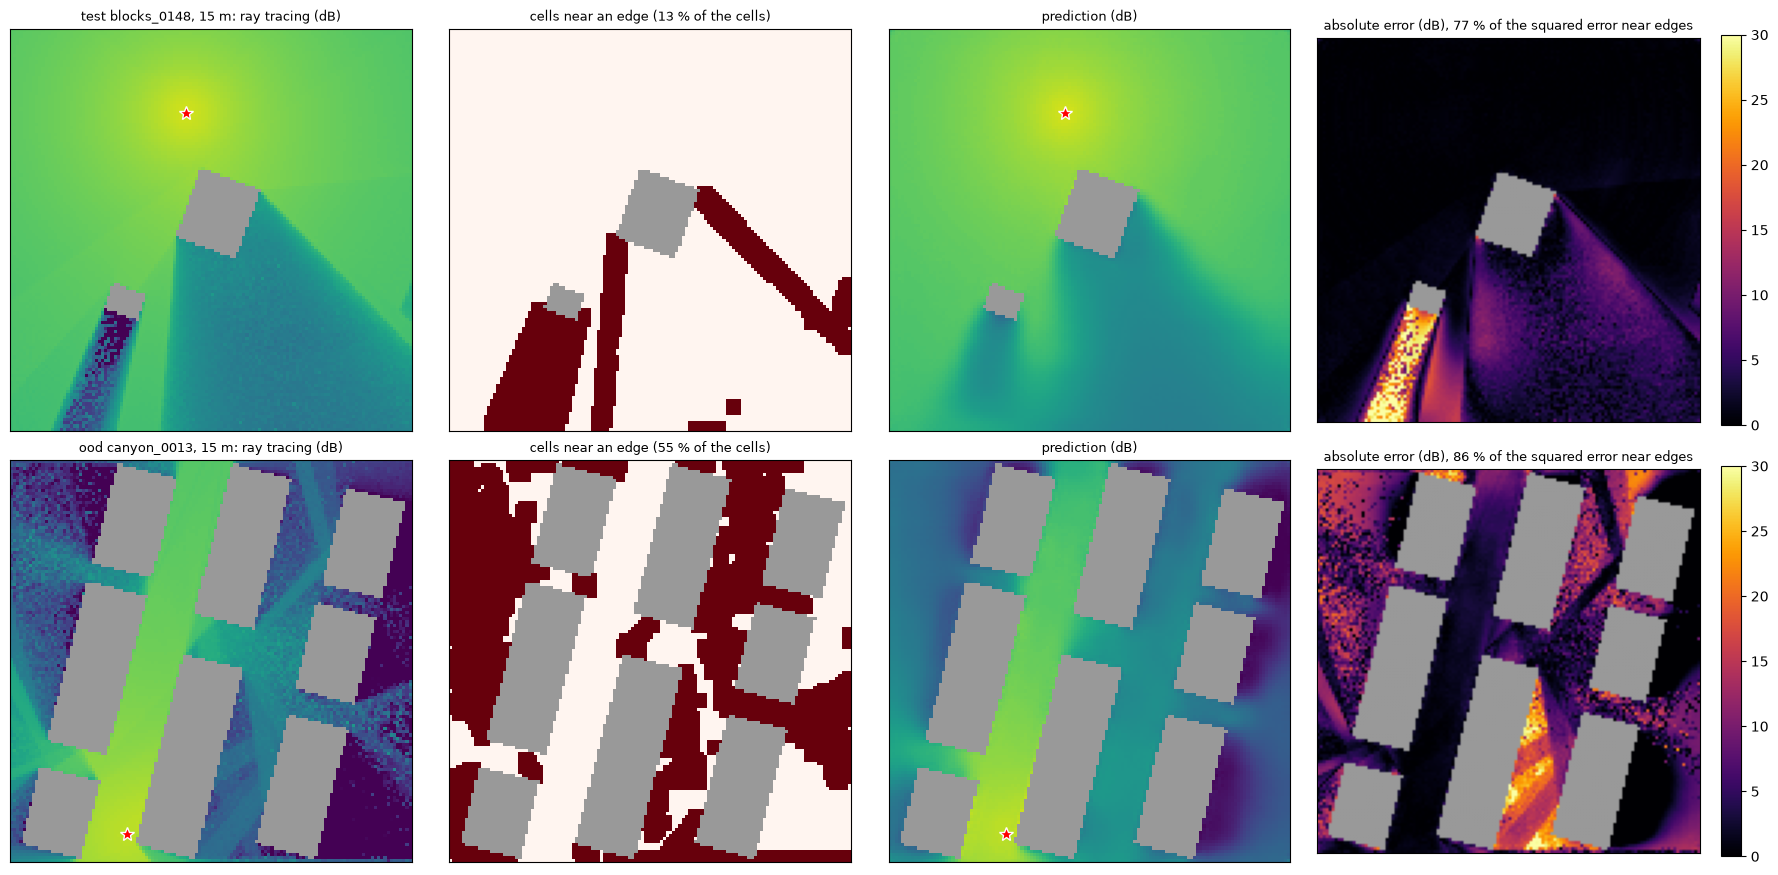

In [44]:
@torch.no_grad()
def plot_edge_errors(predict, examples):
    """Ray traced map, cells near an edge, prediction and absolute error, for (split, map index) pairs."""
    fig, axes = plt.subplots(len(examples), 4, figsize=(18, 4.4 * len(examples)), squeeze=False)
    for row, (split, k) in zip(axes, examples):
        h, st, alt, tgt = split.batch([k], DEVICE)
        valid_t = h < alt.view(-1, 1, 1) - 0.5
        near = near_edges(tgt.clamp_min(CFG["floor_threshold_db"]), valid_t)[0].cpu().numpy()
        valid = valid_t[0].cpu().numpy()
        target = tgt.clamp_min(CFG["floor_db"])[0].cpu().numpy()
        pred = predict(h, st, alt)[0].cpu().numpy()
        link = CFG["floor_threshold_db"]
        err = np.abs(np.maximum(pred, link) - np.maximum(target, link))
        name = split.scene_names[int(split.scene_idx[k])]
        show_map(row[0], target, valid, f"{split.name} {name}, {float(alt[0]):.0f} m: ray tracing (dB)",
                 CFG["floor_db"], CFG["max_db"], station=st[0].cpu())
        show_map(row[1], near.astype(float), valid, f"cells near an edge ({100 * near[valid].mean():.0f} % of the cells)",
                 0, 1, cmap="Reds")
        show_map(row[2], pred, valid, "prediction (dB)", CFG["floor_db"], CFG["max_db"], station=st[0].cpu())
        share = 100 * (err[near] ** 2).sum() / (err[valid] ** 2).sum()
        im = show_map(row[3], err, valid, f"absolute error (dB), {share:.0f} % of the squared error near edges",
                      0, 30, cmap="inferno")
        plt.colorbar(im, ax=row[3], fraction=0.046)
    plt.tight_layout()
    plt.show()


plot_edge_errors(retained_predict, [(test_set, EXAMPLE_TEST), (ood_set, EXAMPLE_OOD)])
del retained_model, retained_predict

#### What the analysis shows
* **The error is concentrated near the edges.** On `test`, the cells within 2 cells of an edge are about a third of
  the valid cells (34 %) but carry about two thirds of the squared error (68 %); on `ood` 30 % of the cells carry
  61 %. The RMSE falls from about 9.5 dB on the edge cells to about 3.3 dB (`test`) more than 5 cells away from any
  edge.
* **The walls of the buildings are not the cause.** The cells within 2 cells of a building are about 3.5 % of the
  cells and carry about 7 % of the squared error. The difficult edges are the edges of the signal itself: the borders
  of the shadows behind buildings and of the corridors of strong signal along the streets.

These edges are mostly the boundaries between cells that the station sees directly (line of sight) and cells that it
does not. Study 3 tests two ways of improving them: giving the network this line-of-sight information directly, and
making the errors near edges count more in the loss.

## 12. Study 3: edges of the coverage map
Model `tiny`, retained loss, no treatment of the no-signal cells, same protocol as studies 1 and 2. The first two methods are
compared with the baseline of study 1; the next two add an edge-detection input to the line-of-sight model and are
compared with it; the last one adds a continuous line-of-sight input to the best of these on validation:

| method | what changes | idea |
|---|---|---|
| **line-of-sight input** (`los`) | an 8th input channel: 1 where the segment from the station to the cell passes above every building (line of sight), 0 otherwise | the network receives the main cause of the edges, computed from the geometry, instead of inferring it from the height map |
| **edge-weighted loss** (`edgeweight`) | the pixel terms of the loss count 3 times for the cells near an edge of the ray traced map | the network spends more of its capacity on the transitions, as in the border weight maps of U-Net and edge-weighted losses of image restoration |
| **line of sight + its edges** (`los_losedge`) | 9th input channel: Sobel edge strength of the `los` map | the shadow borders, where diffraction occurs and most of the error lies, are given as explicit lines |
| **line of sight + building edges** (`los_heightedge`) | 9th input channel: Sobel edge strength of the height map | the walls and roof edges of the buildings are given explicitly, as in edge-guided image processing networks |
| **+ continuous line of sight** (`los_heightedge_clearance`) | 10th input channel on top of `los_heightedge`: the clearance of the station-to-cell segment | the binary line of sight does not say how deep a cell lies in the shadow; the clearance separates a cell just behind a roof edge (diffraction) from a cell deep in the shadow |

* **Line-of-sight input.** For every cell of the drone plane, 96 points are taken along the straight segment from the
  station to the cell, and the surface height at each point is read from the height map. The cell is in line of sight
  when the segment is above the surface at every point. The channel is computed on the GPU for every batch, like the
  other inputs, and is rotated and mirrored with them.
* **Edge-detection inputs.** A Sobel filter (3 × 3 convolution, the same as in the gradient term of the combined
  loss) is applied to the `los` map or to the height map, and the magnitude of the derivatives is added as an input
  channel. The line-of-sight channel is kept unchanged.
* **Continuous line of sight (clearance).** The same 96 points as for the line-of-sight channel are used; the
  clearance is the smallest height of the segment above the surface (positive: line of sight; negative: how far
  the segment passes below a roof), divided by 60 m and limited to [−1, 1]. It is added to the model with the lowest
  validation RMSE among the edge-detection inputs (`los_heightedge`: 5.29 dB against 5.32 dB for `los_losedge` and
  5.31 dB for `los`). Like the other inputs, it is computed from the geometry only.
* **Edge-weighted loss.** The edges are found in the ray traced target of each training map (section 5.2); the cells
  within 2 cells of an edge get weight 3 in the L1 and MSE terms of the combined loss, all other cells weight 1.

**Evaluation.** The main metric of this study is the **edge RMSE** `edge_rmse_db` (cells near an edge, prediction
and ray tracing clipped at −130 dB), together with the RMSE of the other cells, the link RMSE, the standard RMSE, the
RMSE near the coverage boundary and the coverage prediction error.

The input channels tested in this study, for three example maps (the least built-up scene of `val`, and the `test` and `ood` examples used in the other figures): line of sight, its edges, the building edges and the clearance, next to the ray traced map. Grey cells are inside buildings taller than the drone.

In [ ]:
# the input channels of study 3 for three example maps: the least built-up scene of val (drone at 30 m),
# and the test and ood examples used in the other figures
sparse_scene = int(np.argmin((val_set.heights > 0.5).float().mean((1, 2))))
maps_of_scene = np.where(val_set.scene_idx.numpy() == sparse_scene)[0]
SPARSE_VAL = int(maps_of_scene[val_set.altitude.numpy()[maps_of_scene] == 30.0][0])
examples = [(val_set, SPARSE_VAL), (test_set, EXAMPLE_TEST), (ood_set, EXAMPLE_OOD)]
cfg_inputs = {**CFG, "in_channels": ["height", "los", "los_edge", "height_edge", "clearance"]}
hs = CFG["height_scale"]

fig, axes = plt.subplots(len(examples), 6, figsize=(28, 4.9 * len(examples)))
for row, (split, k) in zip(axes, examples):
    h, st, alt, tgt = split.batch([k], DEVICE)
    x, valid_t = make_inputs(h, st, alt, cfg_inputs)
    x, valid, s = x[0].cpu().numpy(), valid_t[0].cpu().numpy(), st[0].cpu()
    name = split.scene_names[int(split.scene_idx[k])]
    im = show_map(row[0], x[0] * hs, title=f"{split.name} {name}, {float(alt[0]):.0f} m: height (m)", cmap="magma",
                  station=s)
    plt.colorbar(im, ax=row[0], fraction=0.046)
    show_map(row[1], x[1], valid, "los: line of sight (1 = visible)", 0, 1, cmap="Greys_r", station=s)
    im = show_map(row[2], x[2], title="los_edge: Sobel of the LOS map", vmin=0, vmax=0.6, cmap="inferno", station=s)
    plt.colorbar(im, ax=row[2], fraction=0.046)
    im = show_map(row[3], x[3], title="height_edge: Sobel of the height map", vmin=0, vmax=0.6, cmap="inferno",
                  station=s)
    plt.colorbar(im, ax=row[3], fraction=0.046)
    im = show_map(row[4], x[4] * hs, valid, "clearance: continuous line of sight (m)", -20, 20, cmap="RdBu", station=s)
    plt.colorbar(im, ax=row[4], fraction=0.046, label="m (blue: above the buildings, red: below)")
    im = show_map(row[5], tgt.clamp_min(CFG["floor_db"])[0].cpu(), valid, "ray tracing (dB), for comparison",
                  CFG["floor_db"], CFG["max_db"], station=s)
    plt.colorbar(im, ax=row[5], fraction=0.046)
plt.tight_layout()
plt.show()

In [46]:
tiny_los = run_experiment("tiny_combo_los", "tiny", BEST_LOSS, in_channels=list(CFG["in_channels"]) + ["los"])

tiny_combo_los: finished earlier, results loaded from runs\loss_and_size_study\tiny_combo_los\results.json


In [47]:
tiny_edgeweight = run_experiment("tiny_combo_edgeweight", "tiny", BEST_LOSS, edge_weight=3.0)

tiny_combo_edgeweight: finished earlier, results loaded from runs\loss_and_size_study\tiny_combo_edgeweight\results.json


In [48]:
tiny_los_losedge = run_experiment("tiny_combo_los_losedge", "tiny", BEST_LOSS,
                                  in_channels=list(CFG["in_channels"]) + ["los", "los_edge"])

=== tiny_combo_los_losedge: model tiny (3.68 M parameters), loss combo, no-signal cells: none
12960 training maps, 810 steps per epoch, 16200 steps in total


epoch 1/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch   1/20 | train loss 2.620e-01 | val RMSE 7.857 dB (MAE 5.503, cov err@-110 7.955%) | lr 1.0e-04 | 79 s  *best*


epoch 2/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch   2/20 | train loss 7.011e-02 | val RMSE 6.408 dB (MAE 4.182, cov err@-110 6.792%) | lr 9.9e-05 | 66 s  *best*


epoch 3/20:   0%|          | 0/810 [00:00<?, ?it/s]

... (31 outputs left out)

epoch 19/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch  19/20 | train loss 5.545e-02 | val RMSE 5.333 dB (MAE 3.265, cov err@-110 5.271%) | lr 1.1e-05 | 66 s  *best*


epoch 20/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch  20/20 | train loss 5.546e-02 | val RMSE 5.322 dB (MAE 3.238, cov err@-110 5.264%) | lr 1.0e-05 | 65 s  *best*


In [49]:
tiny_los_heightedge = run_experiment("tiny_combo_los_heightedge", "tiny", BEST_LOSS,
                                     in_channels=list(CFG["in_channels"]) + ["los", "height_edge"])

=== tiny_combo_los_heightedge: model tiny (3.68 M parameters), loss combo, no-signal cells: none
12960 training maps, 810 steps per epoch, 16200 steps in total


epoch 1/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch   1/20 | train loss 2.613e-01 | val RMSE 8.009 dB (MAE 5.628, cov err@-110 8.089%) | lr 1.0e-04 | 66 s  *best*


epoch 2/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch   2/20 | train loss 7.064e-02 | val RMSE 6.331 dB (MAE 4.082, cov err@-110 6.637%) | lr 9.9e-05 | 65 s  *best*


epoch 3/20:   0%|          | 0/810 [00:00<?, ?it/s]

... (31 outputs left out)

epoch 19/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch  19/20 | train loss 5.543e-02 | val RMSE 5.290 dB (MAE 3.222, cov err@-110 5.234%) | lr 1.1e-05 | 66 s  *best*


epoch 20/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch  20/20 | train loss 5.540e-02 | val RMSE 5.291 dB (MAE 3.210, cov err@-110 5.206%) | lr 1.0e-05 | 66 s


In [59]:
tiny_los_heightedge_clearance = run_experiment("tiny_combo_los_heightedge_clearance", "tiny", BEST_LOSS,
                                               in_channels=list(CFG["in_channels"]) + ["los", "height_edge", "clearance"])

=== tiny_combo_los_heightedge_clearance: model tiny (3.68 M parameters), loss combo, no-signal cells: none
12960 training maps, 810 steps per epoch, 16200 steps in total


epoch 1/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch   1/20 | train loss 2.394e-01 | val RMSE 8.707 dB (MAE 6.904, cov err@-110 7.892%) | lr 1.0e-04 | 64 s  *best*


epoch 2/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch   2/20 | train loss 7.250e-02 | val RMSE 6.361 dB (MAE 4.287, cov err@-110 6.558%) | lr 9.9e-05 | 64 s  *best*


epoch 3/20:   0%|          | 0/810 [00:00<?, ?it/s]

... (31 outputs left out)

epoch 19/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch  19/20 | train loss 5.500e-02 | val RMSE 5.238 dB (MAE 3.175, cov err@-110 5.098%) | lr 1.1e-05 | 64 s  *best*


epoch 20/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch  20/20 | train loss 5.500e-02 | val RMSE 5.235 dB (MAE 3.154, cov err@-110 5.110%) | lr 1.0e-05 | 64 s  *best*


### 12.1 Comparison of the edge methods
All values in dB unless stated otherwise; the baseline is the retained run of study 1; the edge-detection inputs are compared with `tiny_combo_los`, the clearance input with `tiny_combo_los_heightedge`.

In [60]:
edge_results = [best_loss_run, tiny_los, tiny_edgeweight, tiny_los_losedge, tiny_los_heightedge,
                tiny_los_heightedge_clearance]
edge_analysis = {r["name"]: range_analysis(r) for r in edge_results}
pd.DataFrame([pd.Series({
    "val edge RMSE": edge_analysis[r["name"]]["summary"]["val"]["edge_rmse_db"],
    "test edge RMSE": edge_analysis[r["name"]]["summary"]["test"]["edge_rmse_db"],
    "ood edge RMSE": edge_analysis[r["name"]]["summary"]["ood"]["edge_rmse_db"],
    "test non-edge RMSE": edge_analysis[r["name"]]["summary"]["test"]["non_edge_rmse_db"],
    "ood non-edge RMSE": edge_analysis[r["name"]]["summary"]["ood"]["non_edge_rmse_db"],
    "val link RMSE": edge_analysis[r["name"]]["summary"]["val"]["rmse_link_db"],
    "test link RMSE": edge_analysis[r["name"]]["summary"]["test"]["rmse_link_db"],
    "ood link RMSE": edge_analysis[r["name"]]["summary"]["ood"]["rmse_link_db"],
    "val RMSE": edge_analysis[r["name"]]["summary"]["val"]["rmse_db"],
    f"test boundary RMSE @{T_REF:g}": edge_analysis[r["name"]]["summary"]["test"][f"boundary_rmse@{T_REF:g}"],
    f"test cov. error @{T_REF:g} (%)": 100 * edge_analysis[r["name"]]["summary"]["test"][f"cov_err@{T_REF:g}"],
    f"ood cov. error @{T_REF:g} (%)": 100 * edge_analysis[r["name"]]["summary"]["ood"][f"cov_err@{T_REF:g}"]},
    name=r["name"]) for r in edge_results])

,val edge RMSE,test edge RMSE,ood edge RMSE,test non-edge RMSE,ood non-edge RMSE,val link RMSE,test link RMSE,ood link RMSE,val RMSE,test boundary RMSE @-110,test cov. error @-110 (%),ood cov. error @-110 (%)
tiny_combo,8.549,8.655,9.146,4.241,4.725,5.499,5.667,5.812,6.160,10.769,6.168,7.857
tiny_combo_los,7.498,7.739,8.027,3.536,4.043,4.647,4.866,4.921,5.314,10.480,5.891,6.752
tiny_combo_edgeweight,8.490,8.652,9.036,4.369,4.824,5.534,5.721,5.836,6.191,10.675,6.247,7.762
tiny_combo_los_losedge,7.508,7.722,7.964,3.527,3.971,4.655,4.853,4.892,5.322,10.425,5.834,6.635
tiny_combo_los_heightedge,7.464,7.638,8.010,3.445,3.996,4.603,4.796,4.917,5.290,10.154,5.800,6.854
tiny_combo_los_heightedge_clearance,7.389,7.680,7.839,3.479,3.908,4.574,4.801,4.791,5.235,10.380,5.739,6.434


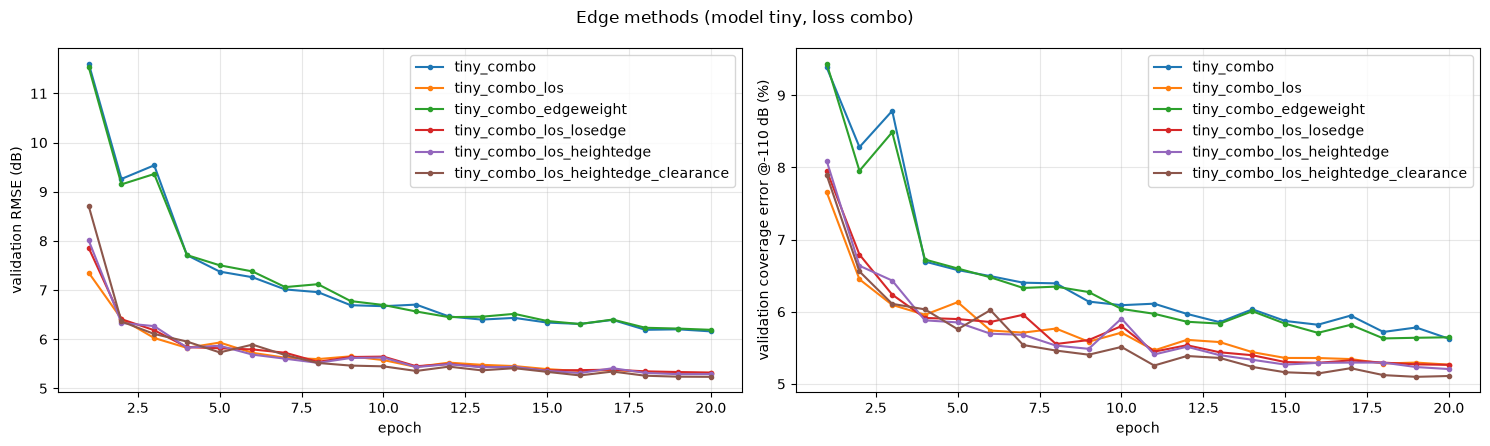

In [61]:
plot_validation_curves(edge_results, f"Edge methods (model tiny, loss {BEST_LOSS})")

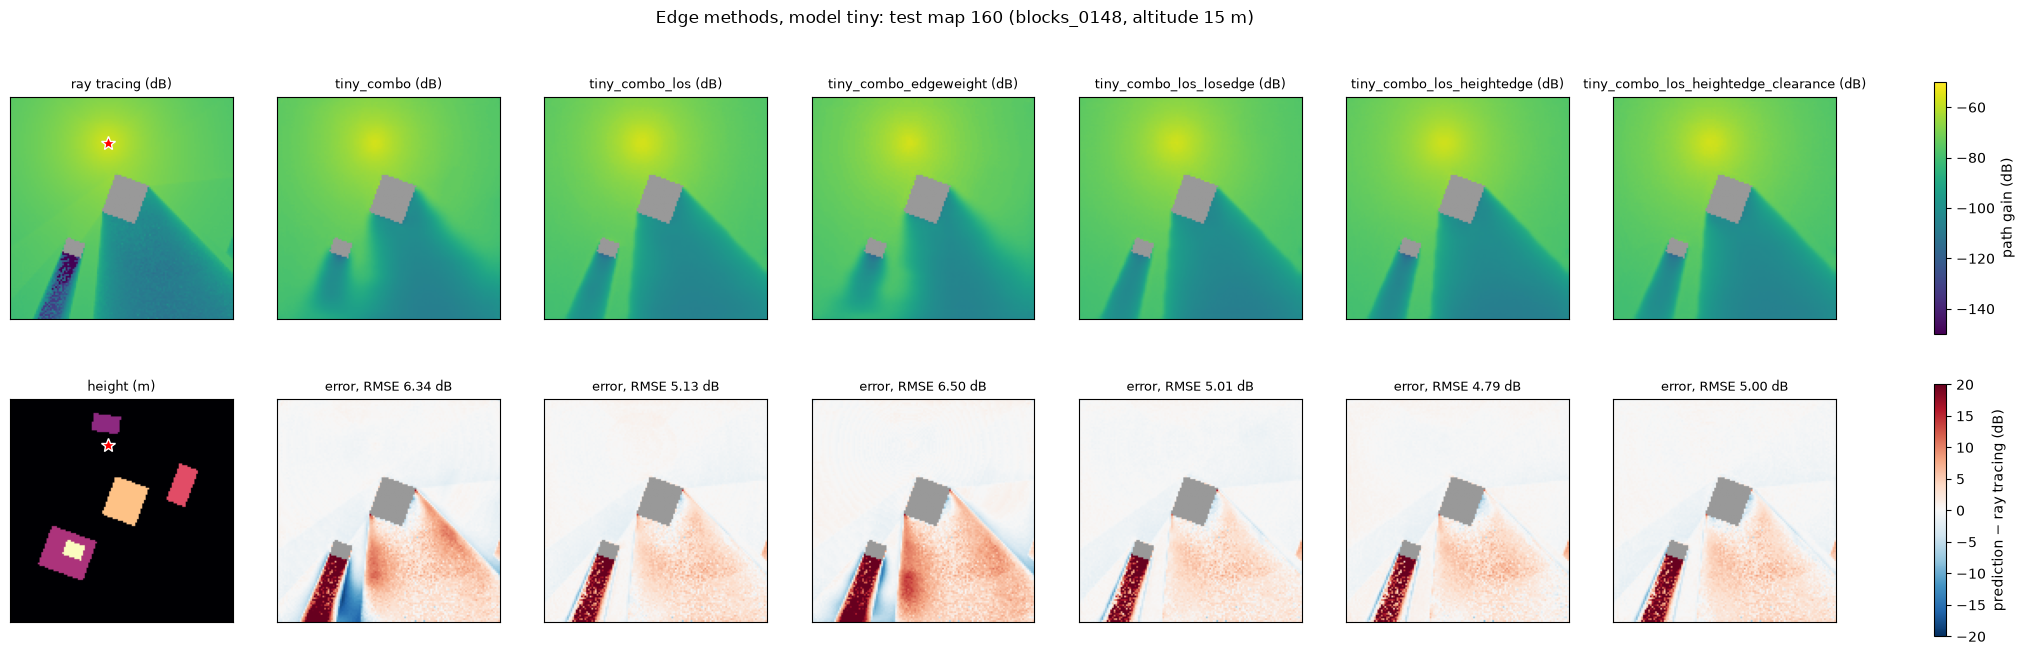

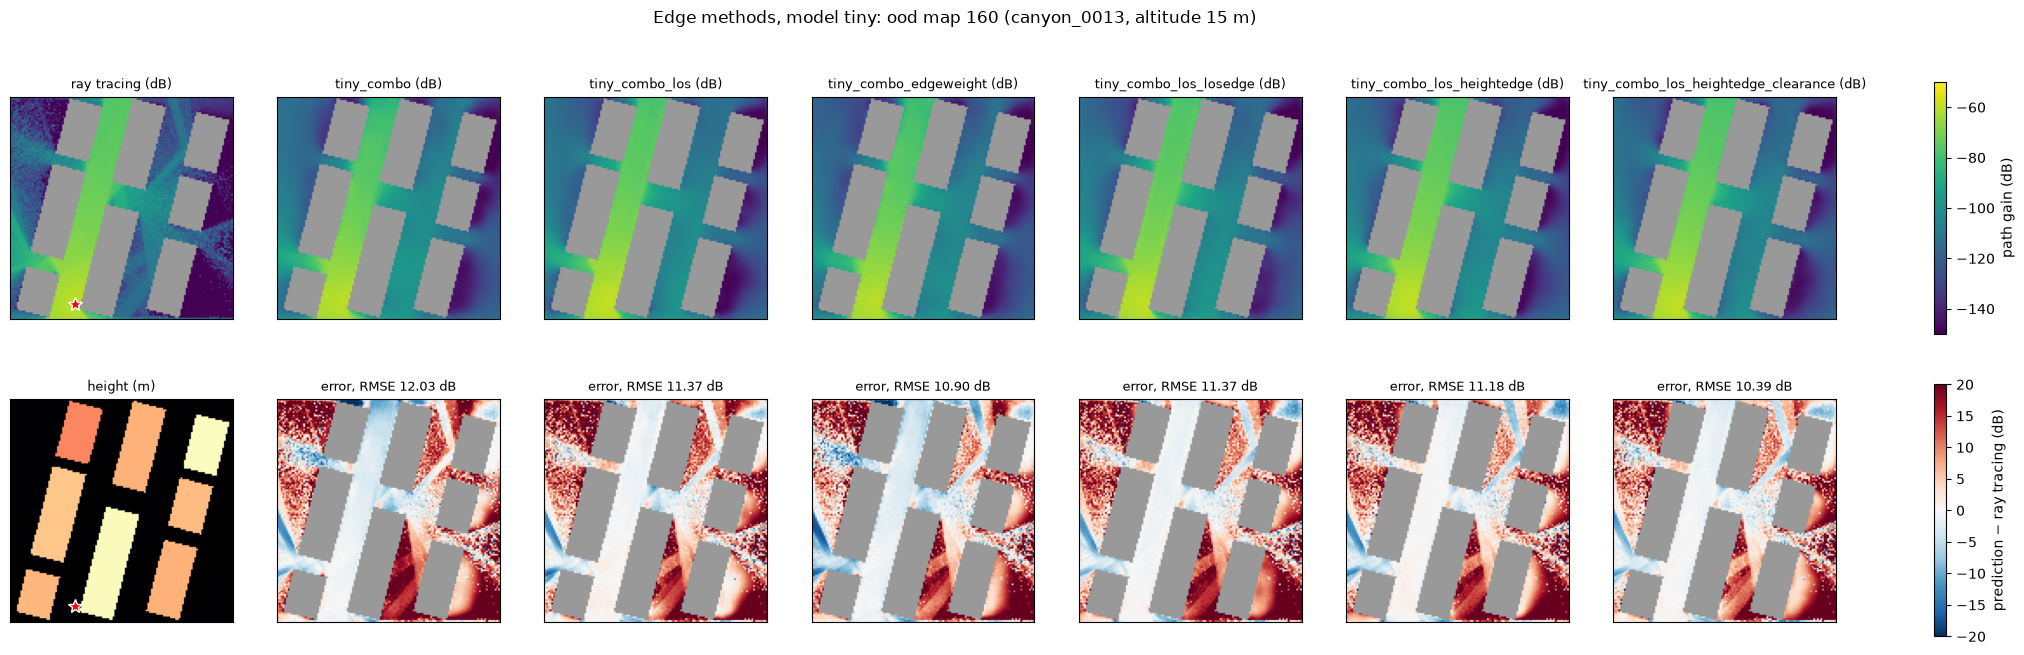

In [62]:
plot_predictions(edge_results, test_set, EXAMPLE_TEST, "Edge methods, model tiny")
plot_predictions(edge_results, ood_set, EXAMPLE_OOD, "Edge methods, model tiny")

#### Observations
* **The line-of-sight input brings the largest gain of the notebook:** RMSE 5.31 dB against 6.16 dB on `val` (−14 %),
  6.27 against 7.27 dB on `ood`; edge RMSE −11 % and other cells −17 % on `test`; false links on `ood` 11.5 % against
  15.9 %.
* **The edge-weighted loss has no effect** (validation RMSE 6.19 against 6.16 dB): what the network lacked was
  geometric information, not emphasis in the loss.
* **Edge-detection inputs add little on top of the line of sight:** LOS edges 5.32 dB and building edges 5.29 dB on
  `val`, against 5.31 dB; building edges lower the boundary RMSE on `test` (10.15 against 10.48 dB) but not the `ood`
  RMSE (6.35 against 6.27 dB).
* **The clearance gives the best model of the study:** RMSE 5.235 dB on `val`, link RMSE 4.57 dB, edge RMSE 7.39 dB,
  and the lowest `ood` RMSE (6.12 dB), `ood` coverage error (6.4 %) and `ood` false links (10.1 %).
* The added channels cost about 0.1 ms per map (1.35 against 1.24 ms in batches of 32).
* The differences between the line-of-sight variants are a few hundredths of a dB from one run each; section 12.2
  checks whether they hold with other seeds.

### 12.2 Robustness to the random seed
The differences between the best configurations of study 3 are a few hundredths of a dB, and each configuration was
trained once (seed 0). The seed sets the initial weights, the order of the training batches and the random rotations
and mirrors, so a second training of the same configuration does not give exactly the same model. To tell whether
the differences are real, the last 3 configurations of study 3 (line of sight with the edges of the line-of-sight
map, with the building edges, and with the building edges and the clearance) are trained again with seeds 1 and 2,
all other settings unchanged. With the existing run (seed 0), each configuration then has 3 runs.

In [63]:
SEEDS = (1, 2)
N_REFERENCE = 3                                                    # the last 3 configurations of study 3


def settings_of(result):
    """Settings of an experiment that differ from CFG (inputs, edge weighting, ...), to train it again."""
    fixed = {"model_size", "loss", "floor_method", "select_metric", "seed"}
    same = lambda a, b: json.dumps(a, default=list, sort_keys=True) == json.dumps(b, default=list, sort_keys=True)
    return {k: v for k, v in result["cfg"].items() if k in CFG and k not in fixed and not same(v, CFG[k])}


reference_runs = edge_results[-N_REFERENCE:]
for r in reference_runs:
    print(f"{r['name']}: validation RMSE {edge_analysis[r['name']]['summary']['val']['rmse_db']:.3f} dB, "
          f"settings {settings_of(r)}")

tiny_combo_los_losedge: validation RMSE 5.322 dB, settings {'in_channels': ['height', 'rel_height', 'valid', 'tx', 'fspl', 'tx_z', 'altitude', 'los', 'los_edge']}
tiny_combo_los_heightedge: validation RMSE 5.290 dB, settings {'in_channels': ['height', 'rel_height', 'valid', 'tx', 'fspl', 'tx_z', 'altitude', 'los', 'height_edge']}
tiny_combo_los_heightedge_clearance: validation RMSE 5.235 dB, settings {'in_channels': ['height', 'rel_height', 'valid', 'tx', 'fspl', 'tx_z', 'altitude', 'los', 'height_edge', 'clearance']}


In [64]:
seed_runs = {r["name"]: [r] for r in reference_runs}                     # seed 0: the runs of section 12
for r in reference_runs:
    for seed in SEEDS:
        seed_runs[r["name"]].append(run_experiment(f"{r['name']}_seed{seed}", r["model_size"], r["loss"],
                                                   r.get("floor_method", "none"), seed=seed, **settings_of(r)))

=== tiny_combo_los_losedge_seed1: model tiny (3.68 M parameters), loss combo, no-signal cells: none
12960 training maps, 810 steps per epoch, 16200 steps in total


epoch 1/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch   1/20 | train loss 3.035e-01 | val RMSE 15.481 dB (MAE 14.123, cov err@-110 15.941%) | lr 1.0e-04 | 65 s  *best*


epoch 2/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch   2/20 | train loss 8.307e-02 | val RMSE 6.282 dB (MAE 4.004, cov err@-110 6.379%) | lr 9.9e-05 | 65 s  *best*


epoch 3/20:   0%|          | 0/810 [00:00<?, ?it/s]

... (231 outputs left out)

epoch 19/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch  19/20 | train loss 5.523e-02 | val RMSE 5.313 dB (MAE 3.243, cov err@-110 5.204%) | lr 1.1e-05 | 61 s


epoch 20/20:   0%|          | 0/810 [00:00<?, ?it/s]

epoch  20/20 | train loss 5.513e-02 | val RMSE 5.279 dB (MAE 3.187, cov err@-110 5.177%) | lr 1.0e-05 | 62 s


#### Training curves per configuration and per seed
Validation RMSE after every epoch. First figure: one panel per configuration, with its 3 seeds. Second figure: one panel per seed, with the 3 configurations.

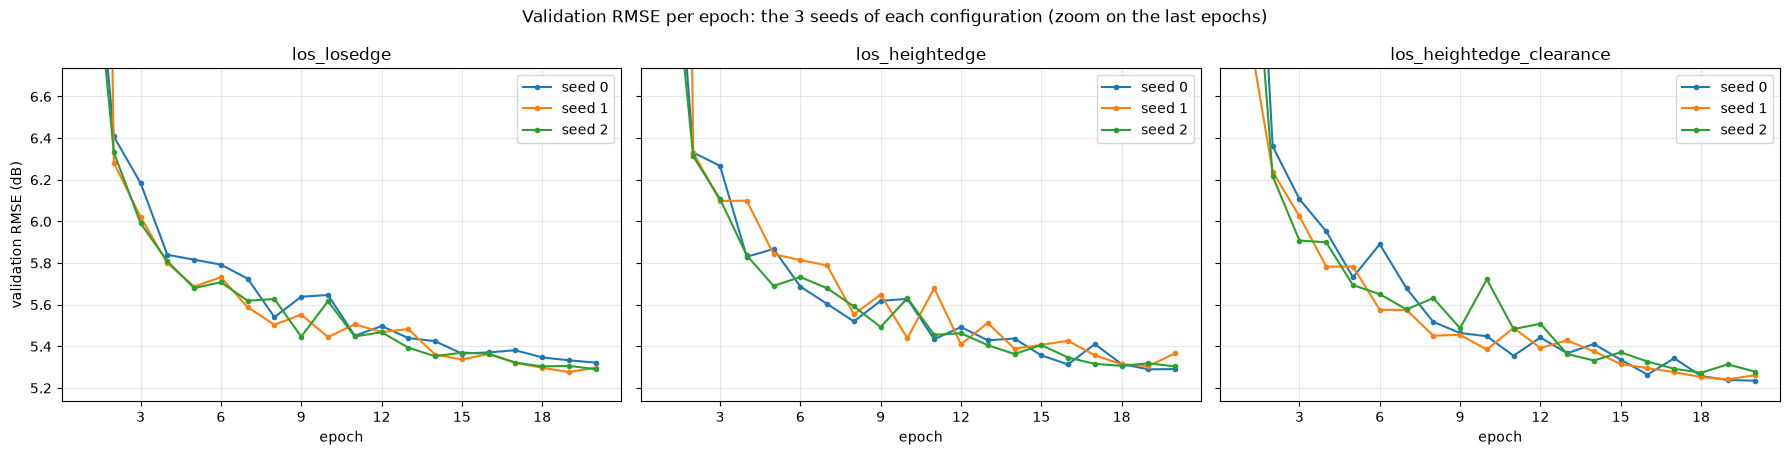

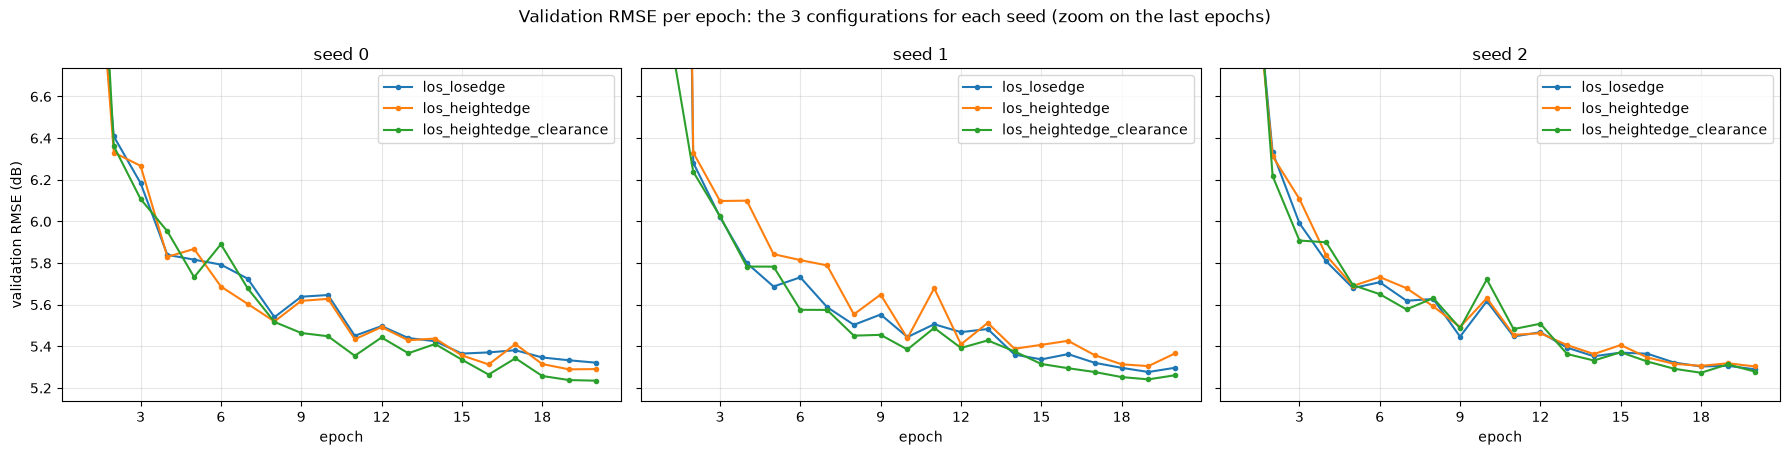

In [65]:
SEED_LIST = (0,) + tuple(SEEDS)                                     # seed 0 = the runs of section 12
short = lambda name: name.replace("tiny_combo_", "")


def plot_curves(ax, runs, labels, title):
    for r, label in zip(runs, labels):
        ep = [h["epoch"] for h in r["history"]]
        ax.plot(ep, [h["val_rmse_db"] for h in r["history"]], marker="o", ms=3, label=label)
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend()


all_curves = [h["val_rmse_db"] for runs in seed_runs.values() for r in runs for h in r["history"]]
y_range = (min(all_curves) - 0.1, min(all_curves) + 1.5)             # zoom on the last epochs

# 1) one panel per configuration: its 3 seeds
fig, axes = plt.subplots(1, len(seed_runs), figsize=(6 * len(seed_runs), 4.6), sharey=True)
for ax, (name, runs) in zip(axes, seed_runs.items()):
    plot_curves(ax, runs, [f"seed {s}" for s in SEED_LIST], short(name))
axes[0].set_ylabel("validation RMSE (dB)")
axes[0].set_ylim(*y_range)
fig.suptitle("Validation RMSE per epoch: the 3 seeds of each configuration (zoom on the last epochs)")
plt.tight_layout()
plt.show()

# 2) one panel per seed: the 3 configurations
fig, axes = plt.subplots(1, len(SEED_LIST), figsize=(6 * len(SEED_LIST), 4.6), sharey=True)
for ax, (i, seed) in zip(axes, enumerate(SEED_LIST)):
    plot_curves(ax, [runs[i] for runs in seed_runs.values()], [short(n) for n in seed_runs], f"seed {seed}")
axes[0].set_ylabel("validation RMSE (dB)")
axes[0].set_ylim(*y_range)
fig.suptitle("Validation RMSE per epoch: the 3 configurations for each seed (zoom on the last epochs)")
plt.tight_layout()
plt.show()

#### Observations
Validation, test and `ood` RMSE (dB) of the best checkpoint of each run, and their mean over the 3 seeds:

| configuration | val (seeds 0 / 1 / 2) | val mean | test mean | ood mean |
|---|---|---|---|---|
| LOS + LOS edges | 5.322 / 5.277 / 5.290 | 5.296 | 5.608 | 6.243 |
| LOS + building edges | 5.290 / 5.305 / 5.304 | 5.300 | 5.602 | 6.289 |
| LOS + building edges + clearance | 5.235 / 5.241 / 5.273 | **5.250** | **5.586** | **6.212** |

* **The seed alone moves the results by up to 0.05 dB on `val`** and up to 0.14 dB on `ood`: as much as the
  differences between the configurations measured with one run.
* **The clearance gain is real:** the clearance model has the lowest validation RMSE for every seed, 0.05 dB below the
  other two on average, and the lowest mean on `test` and `ood`.
* **LOS edges and building edges are tied** (5.296 against 5.300 dB): the advantage of building edges seen with seed 0
  was chance.
* The `ood` RMSE of the seed-0 clearance run (6.12 dB) was favourable; over the 3 seeds it is 6.21 dB.
* **Retained configuration:** line of sight + building edges + clearance, trained for 60 epochs in section 13.

## 13. Final model: longer training
All studies use 20 epochs, which is enough to compare methods trained in the same way but not to reach convergence:
the validation RMSE of every run was still decreasing at the last epochs. The configuration retained in section 12.2
(model `tiny`, combined loss; line-of-sight, building-edge and clearance inputs) is therefore trained again for
**60 epochs** (48,600 steps), with the seed of the protocol (0): the seed check selects the configuration, not a
seed. Everything else is unchanged; the learning rate schedule stretches over the 60 epochs (warm-up, then cosine
decay from 1e-4 to 1e-5), and the checkpoint with the lowest validation RMSE is kept, which protects against
overfitting. The line-of-sight model trained for 60 epochs earlier is kept as a reference.

In [53]:
tiny_los_60 = run_experiment("tiny_combo_los_e60", "tiny", BEST_LOSS,
                             in_channels=list(CFG["in_channels"]) + ["los"], epochs=60)

tiny_combo_los_e60: finished earlier, results loaded from runs\loss_and_size_study\tiny_combo_los_e60\results.json


In [66]:
tiny_final_60 = run_experiment("tiny_combo_los_heightedge_clearance_e60", "tiny", BEST_LOSS,
                               in_channels=list(CFG["in_channels"]) + ["los", "height_edge", "clearance"], epochs=60)

=== tiny_combo_los_heightedge_clearance_e60: model tiny (3.68 M parameters), loss combo, no-signal cells: none
12960 training maps, 810 steps per epoch, 48600 steps in total


epoch 1/60:   0%|          | 0/810 [00:00<?, ?it/s]

epoch   1/60 | train loss 2.394e-01 | val RMSE 8.717 dB (MAE 6.922, cov err@-110 7.897%) | lr 1.0e-04 | 63 s  *best*


epoch 2/60:   0%|          | 0/810 [00:00<?, ?it/s]

epoch   2/60 | train loss 7.248e-02 | val RMSE 6.344 dB (MAE 4.246, cov err@-110 6.581%) | lr 1.0e-04 | 62 s  *best*


epoch 3/60:   0%|          | 0/810 [00:00<?, ?it/s]

... (111 outputs left out)

epoch 59/60:   0%|          | 0/810 [00:00<?, ?it/s]

epoch  59/60 | train loss 5.203e-02 | val RMSE 4.958 dB (MAE 2.951, cov err@-110 4.769%) | lr 1.0e-05 | 61 s


epoch 60/60:   0%|          | 0/810 [00:00<?, ?it/s]

epoch  60/60 | train loss 5.201e-02 | val RMSE 4.959 dB (MAE 2.959, cov err@-110 4.758%) | lr 1.0e-05 | 60 s


### 13.1 Effect of longer training
All values in dB unless stated otherwise. Rows: baseline of study 1 (20 epochs, no line-of-sight input), retained configuration after 20 epochs, line-of-sight model after 60 epochs (reference), retained configuration after 60 epochs.

In [67]:
final_results = [best_loss_run, tiny_los_heightedge_clearance, tiny_los_60, tiny_final_60]
final_analysis = {r["name"]: range_analysis(r) for r in final_results}
pd.DataFrame([pd.Series({
    "epochs": r["cfg"]["epochs"], "best epoch": r["best_epoch"],
    "val RMSE": final_analysis[r["name"]]["summary"]["val"]["rmse_db"],
    "test RMSE": final_analysis[r["name"]]["summary"]["test"]["rmse_db"],
    "ood RMSE": final_analysis[r["name"]]["summary"]["ood"]["rmse_db"],
    "test link RMSE": final_analysis[r["name"]]["summary"]["test"]["rmse_link_db"],
    "ood link RMSE": final_analysis[r["name"]]["summary"]["ood"]["rmse_link_db"],
    "test edge RMSE": final_analysis[r["name"]]["summary"]["test"]["edge_rmse_db"],
    f"test cov. error @{T_REF:g} (%)": 100 * final_analysis[r["name"]]["summary"]["test"][f"cov_err@{T_REF:g}"],
    f"ood cov. error @{T_REF:g} (%)": 100 * final_analysis[r["name"]]["summary"]["ood"][f"cov_err@{T_REF:g}"],
    "test no-signal: link predicted (%)": 100 * final_analysis[r["name"]]["summary"]["test"]["no_signal_false_link"],
    "ood no-signal: link predicted (%)": 100 * final_analysis[r["name"]]["summary"]["ood"]["no_signal_false_link"],
    "training time (min)": r["train_time_min"]},
    name=r["name"]) for r in final_results])

,epochs,best epoch,val RMSE,test RMSE,ood RMSE,test link RMSE,ood link RMSE,test edge RMSE,test cov. error @-110 (%),ood cov. error @-110 (%),test no-signal: link predicted (%),ood no-signal: link predicted (%),training time (min)
tiny_combo,20.0,20.0,6.160,6.416,7.273,5.667,5.812,8.655,6.168,7.857,3.163,15.873,17.631
tiny_combo_los_heightedge_clearance,20.0,20.0,5.235,5.578,6.120,4.801,4.791,7.680,5.739,6.434,2.095,10.129,21.116
tiny_combo_los_e60,60.0,58.0,5.085,5.362,5.903,4.615,4.585,7.397,5.488,6.006,2.168,8.114,65.110
tiny_combo_los_heightedge_clearance_e60,60.0,58.0,4.952,5.227,5.779,4.491,4.477,7.242,5.254,5.910,1.850,7.601,60.405


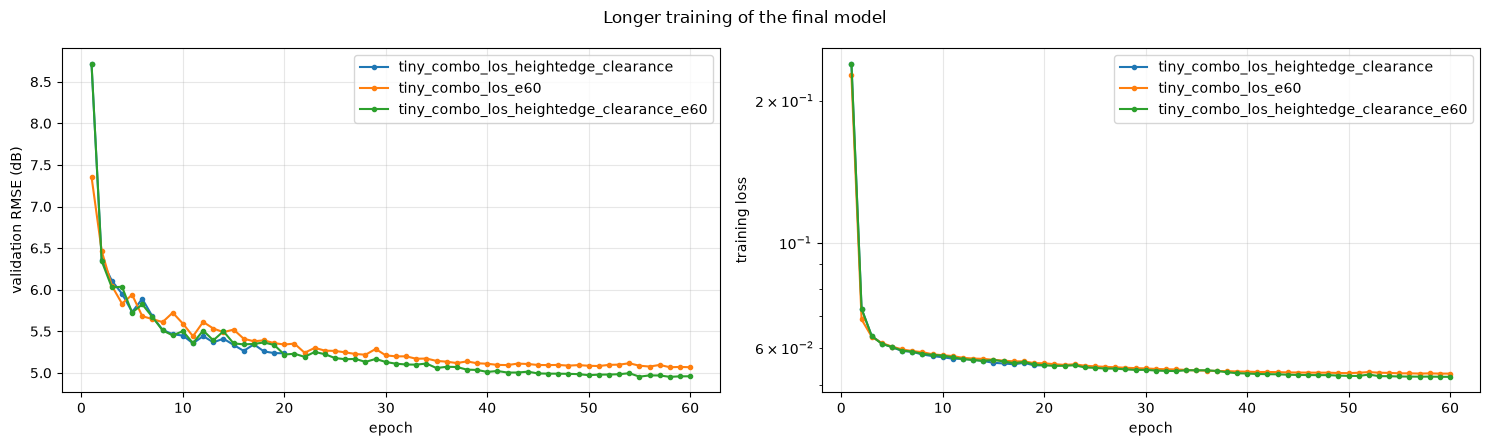

In [68]:
# validation curves and training loss of the 20- and 60-epoch runs (overfitting check)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for r in (tiny_los_heightedge_clearance, tiny_los_60, tiny_final_60):
    ep = [h["epoch"] for h in r["history"]]
    axes[0].plot(ep, [h["val_rmse_db"] for h in r["history"]], marker="o", ms=3, label=f"{r['name']}")
    axes[1].semilogy(ep, [h["train_loss"] for h in r["history"]], marker="o", ms=3, label=f"{r['name']}")
axes[0].set_ylabel("validation RMSE (dB)")
axes[1].set_ylabel("training loss")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Longer training of the final model")
plt.tight_layout()
plt.show()

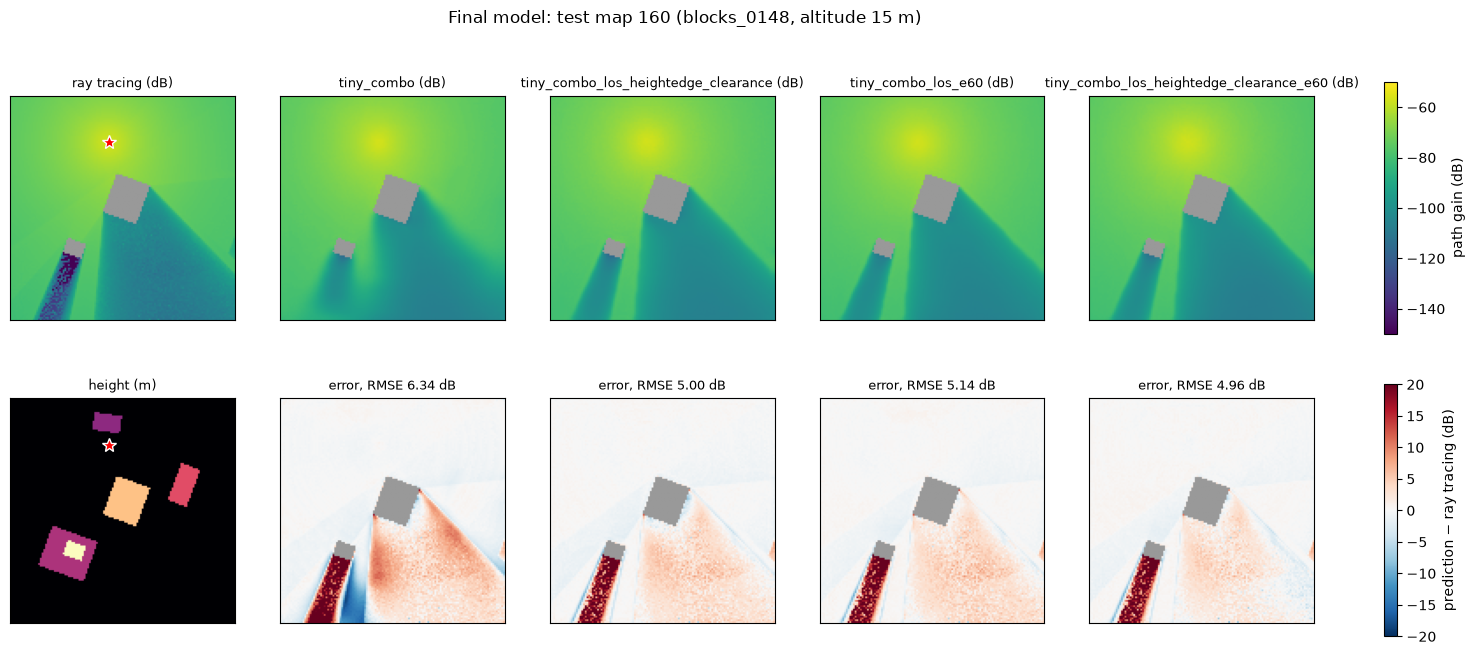

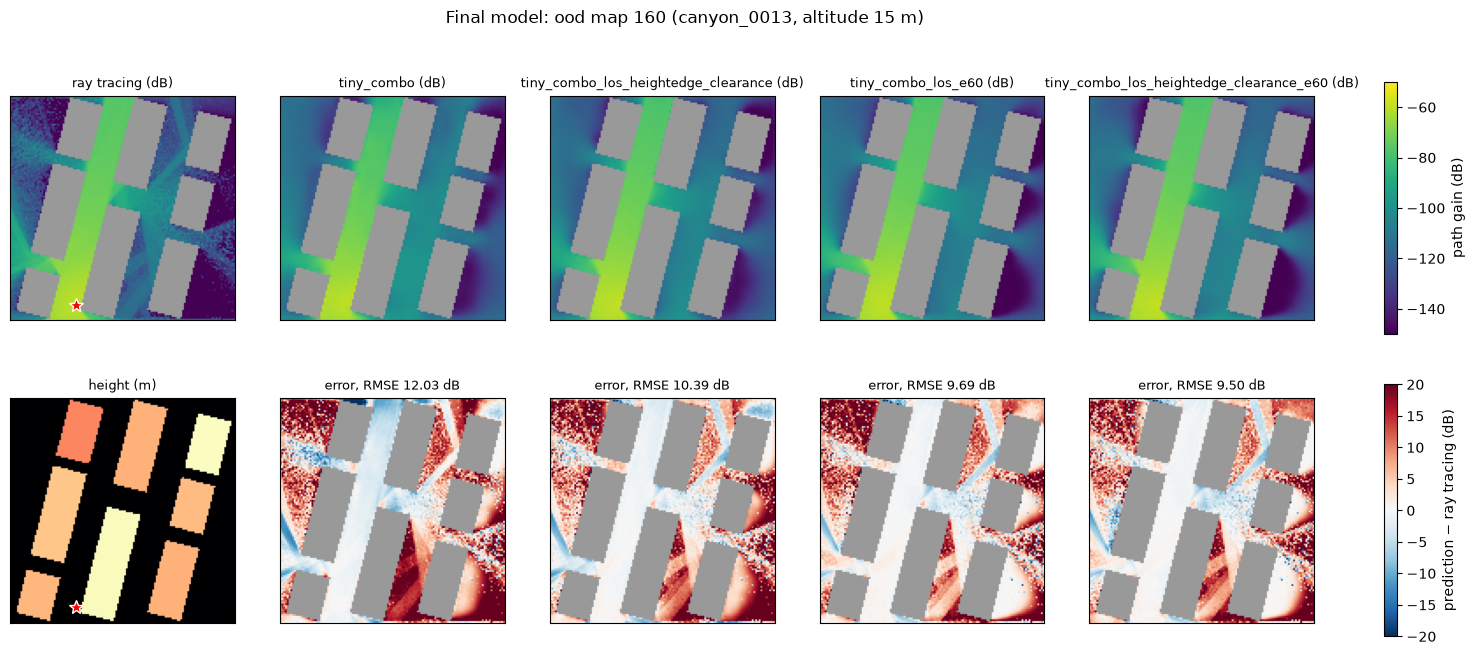

In [69]:
plot_predictions(final_results, test_set, EXAMPLE_TEST, "Final model")
plot_predictions(final_results, ood_set, EXAMPLE_OOD, "Final model")

#### Observations
* **The final model is the most accurate of the notebook:** RMSE 4.95 dB on `val`, 5.23 dB on `test` and 5.78 dB on
  `ood`, that is 20 %, 19 % and 21 % below the baseline of study 1 (6.16, 6.42 and 7.27 dB).
* **60 epochs improve the retained configuration** by 0.3 dB: 5.24 → 4.95 dB on `val`, 5.58 → 5.23 dB on `test`,
  6.12 → 5.78 dB on `ood`.
* **The added inputs keep their advantage after long training:** compared with the line-of-sight model trained for
  60 epochs, RMSE 4.95 against 5.09 dB on `val`, 5.23 against 5.36 dB on `test`, 5.78 against 5.90 dB on `ood`, and
  test edge RMSE 7.24 against 7.40 dB.
* **The coverage decision is safer:** false links on 1.9 % (`test`) and 7.6 % (`ood`) of the no-signal cells, against
  3.2 % and 15.9 % for the baseline; coverage error 5.3 % (`test`) and 5.9 % (`ood`).
* **The training has converged without overfitting:** the validation RMSE stays between 4.95 and 5.00 dB over the last
  ten epochs (best epoch 58) and does not rise while the training loss flattens.
* **Cost:** 60 minutes of training; 1.27 ms per map in batches of 32, about 240 times faster than ray tracing.
* **Remaining weak points:** `downtown` (6.70 dB on `test`), `canyon` (7.08 dB on `ood`) and the lowest altitude
  (7.52 dB at 15 m against 3.32 dB at 60 m on `test`).